# 05 — Neural Network Regression with Biological Data

### Estimating the age of abalone from physical measurements

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 05 of 12  
**Level:** Intermediate  
**Primary tools:** Python, NumPy, pandas, Matplotlib, Keras 3  
**Dataset:** UCI *Abalone* (4,177 animals, 8 features, target = number of shell rings)

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Explain how regression differs from classification in the output layer, the loss, the metrics, and the meaning of a prediction.
2. Show that minimizing squared error estimates the **conditional mean**, absolute error the **conditional median**, and relate both to Gaussian and Laplace likelihoods.
3. Define and differentiate **MSE, MAE, and Huber loss**, and explain their sensitivity to outliers.
4. Derive the **normal equation** of linear regression and show that a `Dense(1)` layer trained with MSE is linear regression.
5. Explain, using the **condition number** of the Hessian, why feature scaling speeds up gradient descent — and why it does not fix collinearity.
6. Compute RMSE, MAE, median absolute error, $R^2$, and "within-$k$-years" accuracy from scratch.
7. Diagnose **underfitting and overfitting** with capacity sweeps and learning curves, using the bias–variance decomposition.
8. Analyse prediction errors: residual plots, Q–Q plots, error by age group, and regression to the mean.
9. Quantify uncertainty with **bootstrap intervals** and with **split-conformal prediction intervals**.

> **What is new compared with Notebook 04?** The target is now a *number*, not a class. The loss functions, the output layer, the metrics, and the whole error analysis change. The mathematics also extends to optimization conditioning and prediction intervals.

## 1. The biological problem and the learning task

The age of an abalone (a marine mollusc) is determined by cutting the shell through the cone, staining it, and **counting growth rings under a microscope** — a slow, laborious procedure that also kills the animal's shell for analysis. Physical measurements such as shell length, diameter, height, and several weights are quick and cheap to obtain. If they predict age reasonably well, fisheries scientists can estimate the age structure of a population without counting rings for every animal.

The number of rings $r$ gives the age in years approximately as

$$
\text{age} \approx r + 1.5 .
$$

### 1.1 Formal task

Each animal is a feature vector $x \in \mathbb{R}^{F}$ and its target is a real number $y$ (age in years). We want a function $f_\theta$ such that

$$
\hat{y} = f_\theta(x) \approx y .
$$

### 1.2 Classification versus regression

| | Classification (Notebook 04) | Regression (this notebook) |
|---|---|---|
| Target | one of $K$ classes | a real number |
| Output layer | $K$ units, softmax | 1 unit, **linear** (no activation) |
| What the model estimates | $P(y = k \mid x)$ | a summary of $P(y \mid x)$, usually the mean |
| Typical loss | cross-entropy | MSE, MAE, Huber |
| Typical metrics | accuracy, F1, confusion matrix | RMSE, MAE, $R^2$, residual analysis |
| A "wrong" prediction is | right or wrong | *close* or *far* |

### 1.3 Why this dataset is instructive

- It is small (CPU-friendly) and real, with a clear biological meaning.
- The features are **strongly correlated** with each other (sizes and weights all grow together), which is a realistic challenge for optimization and interpretation.
- The relation between size and age **saturates**: old animals barely grow, so age is hard to estimate for them. This creates a typical regression pattern, *regression to the mean*, that we will analyse.
- Age is only an *indirect* function of the measurements, so a substantial part of the variance cannot be explained. Knowing the limit of a model is part of the science.

## 2. Set up the environment

We use Keras 3 with the TensorFlow backend. The backend must be selected before importing Keras.

In [ ]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy pandas matplotlib

In [1]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys
import json
import math
import urllib.request
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import keras

SEED = 42
keras.utils.set_random_seed(SEED)

ARTIFACT_DIR = "artifacts_05"      # models and metadata
FIG_DIR = "figures_05"             # exported figures
for folder in (ARTIFACT_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

print("Python :", sys.version.split()[0])
print("Keras  :", keras.__version__, "| backend:", keras.backend.backend())
print("NumPy  :", np.__version__)
print("pandas :", pd.__version__)

Python : 3.11.0
Keras  : 3.15.1 | backend: tensorflow
NumPy  : 2.4.6
pandas : 2.3.3


## 3. Visual style

We reuse the visual style of Notebook 04: a restrained palette, light grids, annotations that point to what matters, and figures exported to a folder (`figures_05`). The three sexes of the dataset (`M` male, `F` female, `I` infant) get one fixed colour each in every figure.

In [3]:
COLORS = {"blue": "#2563EB", "orange": "#F59E0B", "green": "#10B981", "red": "#EF4444",
          "purple": "#8B5CF6", "gray": "#6B7280", "dark": "#111827", "light": "#E5E7EB"}
SEX_COLORS = {"M": COLORS["blue"], "F": COLORS["orange"], "I": COLORS["green"]}
SEX_NAMES = {"M": "Male", "F": "Female", "I": "Infant"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": COLORS["gray"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["light"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": COLORS["dark"], "xtick.color": COLORS["dark"], "ytick.color": COLORS["dark"],
    "font.size": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

SAVE_FIGURES = True
def finish(fig, name, pad=1.0):
    """Tidy the layout, optionally export the figure, and show it."""
    fig.tight_layout(pad=pad)
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()

## 4. The dataset

The file `abalone.data` has one animal per row.

| Column | Meaning | Type |
|---|---|---|
| `sex` | `M` (male), `F` (female), `I` (infant) | categorical |
| `length` | longest shell measurement | continuous |
| `diameter` | perpendicular to length | continuous |
| `height` | with meat in shell | continuous |
| `whole_weight` | whole animal | continuous |
| `shucked_weight` | weight of the meat | continuous |
| `viscera_weight` | gut weight after bleeding | continuous |
| `shell_weight` | after being dried | continuous |
| `rings` | number of rings | integer (**target**) |

The continuous variables were **scaled by dividing by 200** by the dataset's curators (originally millimetres and grams) so that they suit neural networks; we keep this scale. The dataset (Nash *et al.*, 1994) is distributed under a Creative Commons Attribution 4.0 licence; the full citation is in the references at the end.

The cell below downloads the file once into a local `data/` folder. If your computer has no internet access, download `abalone.data` manually from the UCI page and put it into `data/`.

In [4]:
DATA_DIR = "data"
DATA_PATH = os.path.join(DATA_DIR, "abalone.data")
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"
COLUMNS = ["sex", "length", "diameter", "height", "whole_weight",
           "shucked_weight", "viscera_weight", "shell_weight", "rings"]
CONTINUOUS = COLUMNS[1:8]

def load_abalone(path=DATA_PATH, url=DATA_URL):
    """Read the Abalone dataset, downloading it first if it is not available locally."""
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        print("Downloading:", url)
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as error:
            raise RuntimeError(
                f"Could not download the dataset ({error}). Download 'abalone.data' manually from "
                f"https://archive.ics.uci.edu/dataset/1/abalone and save it as '{path}'."
            ) from error
    return pd.read_csv(path, header=None, names=COLUMNS)

df_raw = load_abalone()
display(df_raw.head())

Downloading: https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [5]:
# Sanity checks before any modelling.
assert df_raw.shape == (4177, 9), f"Unexpected shape: {df_raw.shape}"
assert set(df_raw["sex"]) == {"M", "F", "I"}

print("Shape            :", df_raw.shape)
print("Missing values   :", int(df_raw.isna().sum().sum()))
print("Rings range      :", int(df_raw["rings"].min()), "to", int(df_raw["rings"].max()))
print("Sex counts       :", df_raw["sex"].value_counts().to_dict())
print("Duplicated rows  :", int(df_raw.duplicated().sum()))

# A physically impossible value: an animal cannot have a shell height of zero.
n_zero_height = int((df_raw["height"] <= 0).sum())
print(f"\nRows with height <= 0 (measurement errors): {n_zero_height}")

summary = df_raw[CONTINUOUS + ["rings"]].describe().T[["min", "mean", "max", "std"]].round(3)
display(summary)

Shape            : (4177, 9)
Missing values   : 0
Rings range      : 1 to 29
Sex counts       : {'M': 1528, 'I': 1342, 'F': 1307}
Duplicated rows  : 0

Rows with height <= 0 (measurement errors): 2


,min,mean,max,std
length,0.075,0.524,0.815,0.120
diameter,0.055,0.408,0.650,0.099
height,0.000,0.140,1.130,0.042
whole_weight,0.002,0.829,2.826,0.490
shucked_weight,0.001,0.359,1.488,0.222
viscera_weight,0.000,0.181,0.760,0.110
shell_weight,0.002,0.239,1.005,0.139
rings,1.000,9.934,29.000,3.224


**Data cleaning.** The rows with a shell height of zero are measurement or recording errors. We remove them **before** splitting. This decision is based on domain knowledge (a physical impossibility), not on model performance or on the test labels, so it does not leak information. Every cleaning step should be documented and justified in this way.

We also define the target in years, $y = \text{rings} + 1.5$, so that errors have a direct biological meaning (an error of 1.0 means "off by one year").

In [6]:
df = df_raw[df_raw["height"] > 0].reset_index(drop=True).copy()
df["age_years"] = df["rings"] + 1.5
print("Rows after cleaning:", len(df), "(removed", len(df_raw) - len(df), ")")

# One-hot encoding of the categorical feature 'sex'. Column order is fixed and documented.
SEX_COLUMNS = ["sex_F", "sex_I", "sex_M"]
sex_onehot = pd.get_dummies(df["sex"]).reindex(columns=["F", "I", "M"]).astype(float)
sex_onehot.columns = SEX_COLUMNS

FEATURES = CONTINUOUS + SEX_COLUMNS
X = np.hstack([df[CONTINUOUS].to_numpy(dtype="float32"), sex_onehot.to_numpy(dtype="float32")])
y = df["age_years"].to_numpy(dtype="float32")
sex_labels = df["sex"].to_numpy()
n_features = X.shape[1]

print("Feature matrix:", X.shape, "| target:", y.shape)
print("Features      :", FEATURES)
print("One-hot sex example (first 3 animals):")
for i in range(3):
    print(f"  sex={sex_labels[i]} -> {X[i, 7:].astype(int)}")

Rows after cleaning: 4175 (removed 2 )
Feature matrix: (4175, 10) | target: (4175,)
Features      : ['length', 'diameter', 'height', 'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight', 'sex_F', 'sex_I', 'sex_M']
One-hot sex example (first 3 animals):
  sex=M -> [0 0 1]
  sex=M -> [0 0 1]
  sex=F -> [1 0 0]


## 5. Train / validation / test split

For regression there are no classes to stratify on, but we can still keep the **distribution of the target** similar across partitions. We cut the target into quantile bins and split each bin separately (a stratified split on binned targets). With 15% each for validation and test, this gives about 600 animals per partition.

The split happens **before** looking at relationships between features and the target, and before fitting any preprocessing.

In [7]:
def grouped_split_indices(groups, val_fraction=0.15, test_fraction=0.15, seed=SEED):
    """Split indices so that every group is represented proportionally in all three partitions."""
    split_rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for group in np.unique(groups):
        idx = split_rng.permutation(np.flatnonzero(groups == group))
        n_val = max(1, int(round(val_fraction * len(idx))))
        n_test = max(1, int(round(test_fraction * len(idx))))
        val_idx.append(idx[:n_val])
        test_idx.append(idx[n_val:n_val + n_test])
        train_idx.append(idx[n_val + n_test:])
    return [split_rng.permutation(np.concatenate(part)) for part in (train_idx, val_idx, test_idx)]

# Bins of the target: 10 quantile bins (ties in the integer-valued target are handled by digitize).
edges = np.quantile(y, np.linspace(0, 1, 11)[1:-1])
target_bins = np.digitize(y, edges)

train_idx, val_idx, test_idx = grouped_split_indices(target_bins)

X_train, y_train, sex_train = X[train_idx], y[train_idx], sex_labels[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test, sex_test = X[test_idx], y[test_idx], sex_labels[test_idx]

assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(y)
assert len(train_idx) + len(val_idx) + len(test_idx) == len(y)

split_table = pd.DataFrame({
    "n": [len(y_train), len(y_val), len(y_test)],
    "mean age": [y_train.mean(), y_val.mean(), y_test.mean()],
    "std age": [y_train.std(), y_val.std(), y_test.std()],
    "min": [y_train.min(), y_val.min(), y_test.min()],
    "max": [y_train.max(), y_val.max(), y_test.max()],
}, index=["train", "validation", "test"]).round(2)
display(split_table)

,n,mean age,std age,min,max
train,2923,11.43,3.22,2.5,30.5
validation,626,11.45,3.19,4.5,24.5
test,626,11.45,3.29,4.5,28.5


## 6. Exploratory data analysis (training set only)

As in Notebook 04, we explore only the **training** partition, so validation and test data stay unseen.

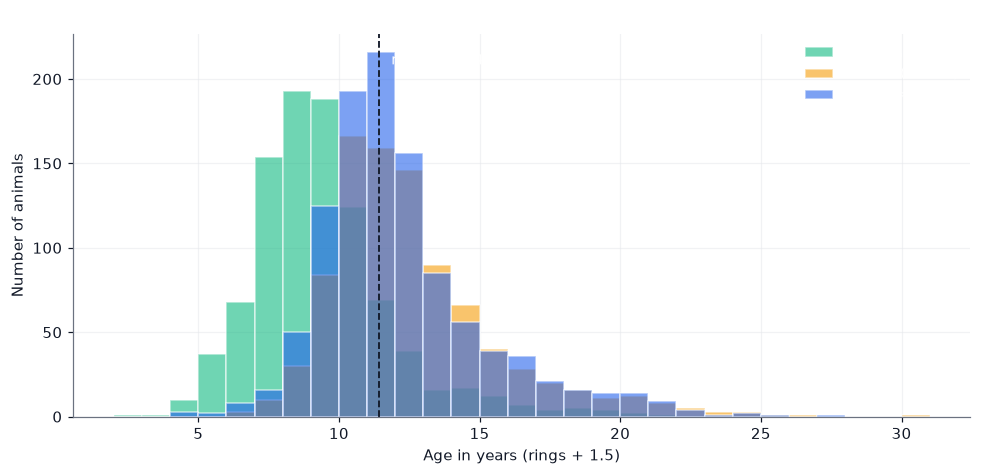

In [8]:
# Figure: distribution of the target by sex.
fig, ax = plt.subplots(figsize=(9, 4.4))
bins = np.arange(y_train.min() - 0.5, y_train.max() + 1.5, 1.0)
for sex in ["I", "F", "M"]:
    ax.hist(y_train[sex_train == sex], bins=bins, alpha=0.60, color=SEX_COLORS[sex],
            edgecolor="white", label=f"{SEX_NAMES[sex]} (n={np.sum(sex_train == sex)})")
ax.axvline(y_train.mean(), color=COLORS["dark"], linestyle="--", linewidth=1.2)
ax.annotate(f"mean = {y_train.mean():.1f} years", (y_train.mean(), ax.get_ylim()[1] * 0.92),
            textcoords="offset points", xytext=(8, 0), fontsize=9)
ax.set_xlabel("Age in years (rings + 1.5)"); ax.set_ylabel("Number of animals")
ax.set_title("Age distribution of the training animals, by sex")
ax.legend()
finish(fig, "01_age_distribution")

The distribution is **right-skewed** with a long tail towards old animals, and infants are concentrated at young ages. Sex is therefore informative about age — but mostly in the sense of "infant or not", while males and females overlap strongly.

### 6.1 Each feature against age

For each continuous feature, we plot the animals as semi-transparent points and add the **median trend**: the median age within quantile bins of the feature. A curve that bends, or flattens, shows that the relationship is not linear.

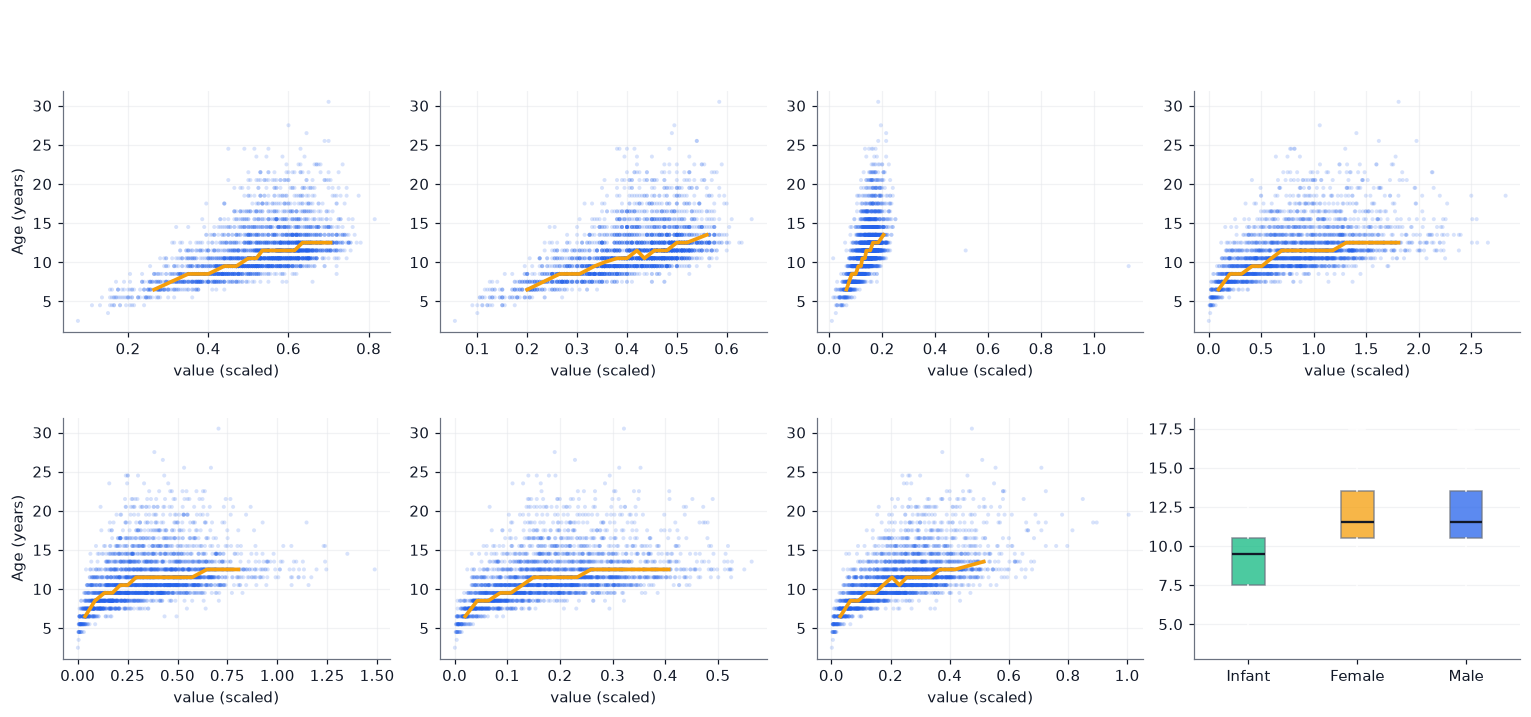

In [9]:
def binned_trend(x, target, n_bins=15):
    """Median of x and of target within quantile bins of x (a simple, assumption-free trend line)."""
    edges_ = np.quantile(x, np.linspace(0, 1, n_bins + 1))
    which = np.clip(np.digitize(x, edges_[1:-1]), 0, n_bins - 1)
    xs = np.array([np.median(x[which == b]) for b in range(n_bins) if np.any(which == b)])
    ys = np.array([np.median(target[which == b]) for b in range(n_bins) if np.any(which == b)])
    return xs, ys

fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
for j, (ax, feature) in enumerate(zip(axes.ravel(), CONTINUOUS)):
    ax.scatter(X_train[:, j], y_train, s=7, alpha=0.18, color=COLORS["blue"], edgecolor="none")
    tx, ty = binned_trend(X_train[:, j], y_train)
    ax.plot(tx, ty, color=COLORS["orange"], linewidth=2.4)
    ax.set_title(feature); ax.set_xlabel("value (scaled)")
    if j % 4 == 0:
        ax.set_ylabel("Age (years)")
# The last panel: age by sex.
ax = axes.ravel()[7]
data = [y_train[sex_train == s] for s in ["I", "F", "M"]]
box_style = dict(patch_artist=True, showfliers=False, medianprops={"color": COLORS["dark"], "linewidth": 1.5})
bp = ax.boxplot(data, **box_style)
for patch, s in zip(bp["boxes"], ["I", "F", "M"]):
    patch.set_facecolor(SEX_COLORS[s]); patch.set_alpha(0.75); patch.set_edgecolor(COLORS["gray"])
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["Infant", "Female", "Male"]); ax.set_title("sex"); ax.grid(axis="x", visible=False)
fig.suptitle("Age against each feature (orange: median trend per quantile bin)", fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.01)
finish(fig, "02_features_vs_age")

Look at the orange trend lines: age rises steeply for small animals and then **flattens** for large ones. Once an abalone is large, its measurements hardly change, while its age keeps increasing. This **saturation** is why old animals are the hardest to date, and it foreshadows the regression-to-the-mean pattern in Section 18.

### 6.2 Correlations between features

The Pearson correlation $r_{ij} = \operatorname{Cov}(x_i, x_j) / (\sigma_i \sigma_j)$ summarizes linear association. Features that are nearly perfectly correlated are **collinear**: they carry almost the same information, and the individual coefficient of each one in a linear model becomes unstable. We will measure the consequence numerically in Section 9.

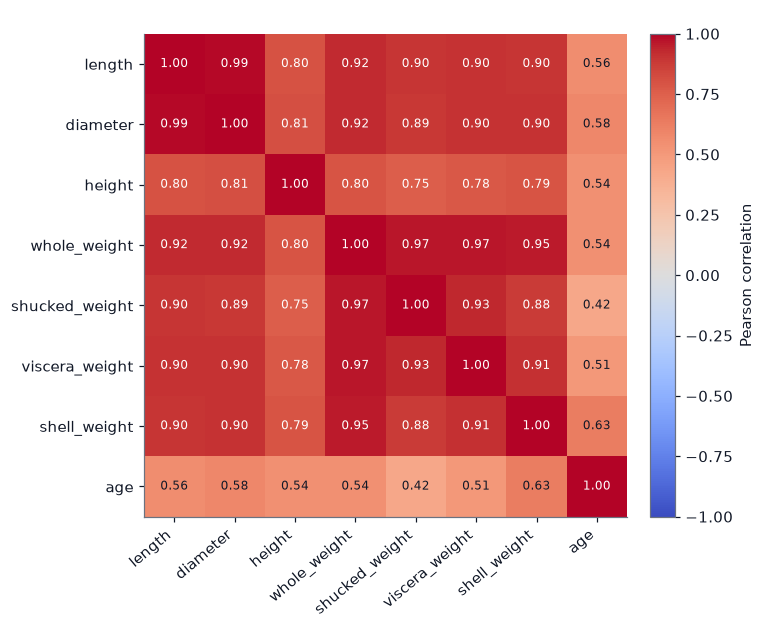

In [10]:
labels_corr = CONTINUOUS + ["age"]
data_corr = np.column_stack([X_train[:, :7], y_train])
corr = np.corrcoef(data_corr, rowvar=False)

fig, ax = plt.subplots(figsize=(7, 5.8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels_corr))); ax.set_xticklabels(labels_corr, rotation=40, ha="right")
ax.set_yticks(range(len(labels_corr))); ax.set_yticklabels(labels_corr)
ax.grid(False)
for i in range(len(labels_corr)):
    for j in range(len(labels_corr)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr[i, j]) > 0.65 else COLORS["dark"])
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
ax.set_title("Feature and target correlations (training set)")
finish(fig, "03_correlations")

Sizes and weights are very strongly correlated with each other, and each one is only moderately correlated with age. The measurements essentially describe one underlying quantity (how big the animal is).

## 7. Mathematics I: what does a regression model estimate?

### 7.1 The conditional mean minimizes squared error

Let $Y$ be the target and $X$ the features. We look for a function $f$ that minimizes the expected squared error $\mathbb{E}\big[(Y - f(X))^2\big]$. Write $\mu(x) = \mathbb{E}[Y \mid X = x]$. Adding and subtracting $\mu(X)$:

$$
\mathbb{E}\big[(Y - f(X))^2\big]
= \underbrace{\mathbb{E}\big[(Y - \mu(X))^2\big]}_{\text{irreducible noise } \sigma^2}
+ \mathbb{E}\big[(\mu(X) - f(X))^2\big]
$$

(the cross term vanishes because $\mathbb{E}[Y - \mu(X) \mid X] = 0$). The first term does not depend on $f$. The second is zero exactly when $f(x) = \mu(x)$. Therefore:

> **The best possible predictor under squared error is the conditional mean $\mu(x) = \mathbb{E}[Y \mid X = x]$, and the smallest achievable error is the noise variance $\sigma^2$.**

For abalone, $\sigma^2$ is large because two animals with the same measurements can have different ages. No model can go below this floor, however large.

### 7.2 The conditional median minimizes absolute error

For absolute error $\mathbb{E}\,|Y - f(X)|$, the minimizer is the **conditional median**. A quick check for a constant $c$: the derivative of $\mathbb{E}|Y - c|$ with respect to $c$ is $P(Y < c) - P(Y > c)$, which is zero when half of the probability lies on each side of $c$.

### 7.3 Likelihood view

Assume $Y \mid X = x$ follows a distribution centred on the prediction $f_\theta(x)$.

| Assumption about the noise | Negative log-likelihood (per sample, up to constants) | Resulting loss |
|---|---|---|
| Gaussian, $Y \sim \mathcal{N}(f_\theta(x), \sigma^2)$ | $\dfrac{(y - f_\theta(x))^2}{2\sigma^2} + \ln\sigma$ | **MSE** |
| Laplace, $Y \sim \operatorname{Laplace}(f_\theta(x), b)$ | $\dfrac{\lvert y - f_\theta(x)\rvert}{b} + \ln 2b$ | **MAE** |

So **MSE assumes Gaussian noise and estimates the mean; MAE assumes heavier-tailed (Laplace) noise and estimates the median**. The Huber loss (next section) is a compromise.

### 7.4 What this means in practice

- If the target distribution is skewed (as here), the conditional mean and median differ: an MSE-trained model aims at the mean, an MAE-trained model at the median.
- "Which loss?" is therefore a *modelling decision about what to predict and how to treat extreme values*, not only a technical choice.

## 8. Mathematics II: MSE, MAE, and Huber loss

For a residual $r = \hat{y} - y$:

$$
\ell_{\text{MSE}}(r) = r^2, \qquad
\ell_{\text{MAE}}(r) = |r|, \qquad
\ell_{\delta}(r) =
\begin{cases}
\dfrac{1}{2} r^2 & |r| \le \delta,\\[4pt]
\delta\left(|r| - \dfrac{\delta}{2}\right) & |r| > \delta .
\end{cases}
$$

The **Huber loss** is quadratic for small residuals and linear for large ones, so it behaves like MSE near zero and like MAE in the tails. Its derivatives with respect to the prediction (the quantities that drive learning) are

$$
\frac{\partial \ell_{\text{MSE}}}{\partial \hat{y}} = 2r, \qquad
\frac{\partial \ell_{\text{MAE}}}{\partial \hat{y}} = \operatorname{sign}(r), \qquad
\frac{\partial \ell_{\delta}}{\partial \hat{y}} = \operatorname{clip}(r, -\delta, \delta) .
$$

**The MSE gradient grows without bound with the residual, so one wild observation can dominate an update.** The MAE gradient has constant magnitude (it is not defined at $r = 0$, and it does not become smaller as the model improves, which can make training less smooth). Huber **clips** the gradient at $\pm\delta$: robust like MAE for outliers, smooth like MSE near the optimum.

### 8.1 Choosing $\delta$

If the noise were Gaussian with standard deviation $\sigma$, the choice $\delta = 1.345\,\sigma$ retains about 95% of the statistical efficiency of MSE while limiting the influence of outliers. In practice $\sigma$ is estimated robustly from the **median absolute deviation (MAD)**:

$$
\hat{\sigma} = 1.4826 \cdot \operatorname{median}\big(|r_i - \operatorname{median}(r)|\big) .
$$

(The factor 1.4826 makes the MAD consistent with the standard deviation for Gaussian data.) We use this in Section 15.

In [11]:
def mse_loss(r): return r**2
def mae_loss(r): return np.abs(r)
def huber_loss(r, delta=1.0):
    a = np.abs(r)
    return np.where(a <= delta, 0.5 * r**2, delta * (a - 0.5 * delta))

def mse_grad(r): return 2 * r
def mae_grad(r): return np.sign(r)
def huber_grad(r, delta=1.0): return np.clip(r, -delta, delta)

# A tiny worked example: three residuals, one of them large.
residuals = np.array([1.0, -2.0, 10.0])
print("Residuals:", residuals)
print(f"MSE   = mean(r^2)      = {np.mean(mse_loss(residuals)):.3f}")
print(f"MAE   = mean(|r|)      = {np.mean(mae_loss(residuals)):.3f}")
print(f"Huber(delta=2)         = {np.mean(huber_loss(residuals, 2.0)):.3f}")
print("The single residual of 10 contributes", f"{100 * 100 / np.sum(residuals**2):.0f}% of the sum of squares,",
      f"but only {100 * 10 / np.sum(np.abs(residuals)):.0f}% of the sum of absolute values.")

# Check the Huber gradient against a numerical derivative.
r_grid = np.array([-3.0, -0.7, 0.4, 2.5])
eps = 1e-6
numeric = (huber_loss(r_grid + eps, 1.0) - huber_loss(r_grid - eps, 1.0)) / (2 * eps)
assert np.allclose(numeric, huber_grad(r_grid, 1.0), atol=1e-6)
print("\nHuber gradient verified numerically.")

Residuals: [ 1. -2. 10.]
MSE   = mean(r^2)      = 35.000
MAE   = mean(|r|)      = 4.333
Huber(delta=2)         = 6.833
The single residual of 10 contributes 95% of the sum of squares, but only 77% of the sum of absolute values.

Huber gradient verified numerically.


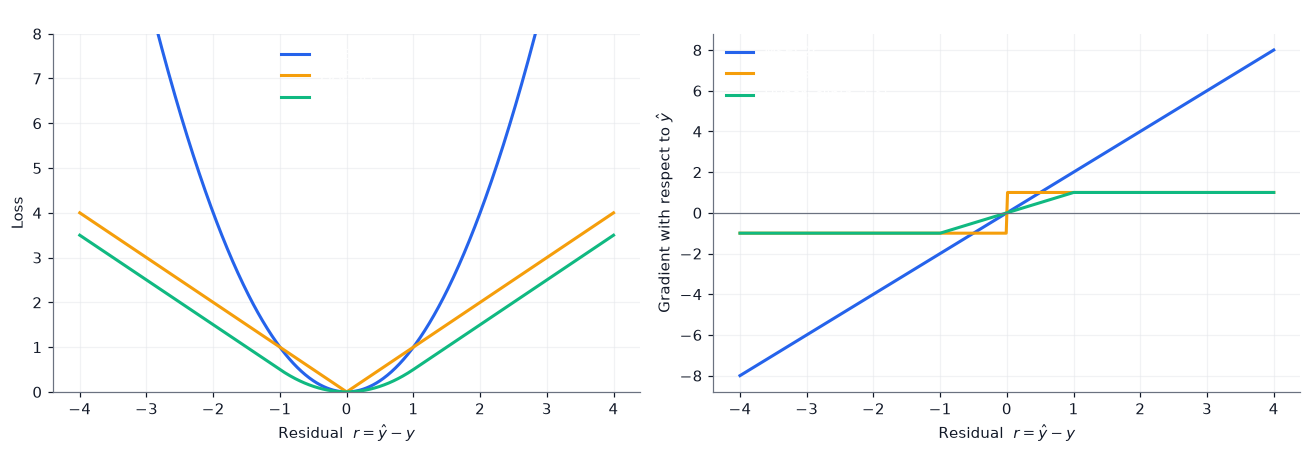

In [12]:
# Figure: the three losses and their gradients.
r = np.linspace(-4, 4, 801)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(r, mse_loss(r), color=COLORS["blue"], label="MSE  $r^2$")
axes[0].plot(r, mae_loss(r), color=COLORS["orange"], label="MAE  $|r|$")
axes[0].plot(r, huber_loss(r, 1.0), color=COLORS["green"], label=r"Huber ($\delta=1$)")
axes[0].set_ylim(0, 8); axes[0].set_xlabel("Residual  $r = \\hat{y} - y$"); axes[0].set_ylabel("Loss")
axes[0].set_title("Loss functions"); axes[0].legend(loc="upper center")

axes[1].plot(r, mse_grad(r), color=COLORS["blue"], label="MSE: $2r$")
axes[1].plot(r, mae_grad(r), color=COLORS["orange"], label="MAE: $\\mathrm{sign}(r)$")
axes[1].plot(r, huber_grad(r, 1.0), color=COLORS["green"], label=r"Huber: clip$(r,\pm\delta)$")
axes[1].axhline(0, color=COLORS["gray"], linewidth=0.8)
axes[1].set_xlabel("Residual  $r = \\hat{y} - y$"); axes[1].set_ylabel("Gradient with respect to $\\hat{y}$")
axes[1].set_title("Gradients: how strongly each residual pulls the model"); axes[1].legend(loc="upper left")
finish(fig, "04_loss_functions")

### 8.2 Robustness in action: estimating a centre in the presence of an outlier

The simplest regression model is a constant $c$ fitted to a sample. Under the three losses, the best constant is the **mean** (MSE), the **median** (MAE), and the **Huber location estimate** (computed iteratively; each point gets a weight $w_i = \min(1, \delta/|r_i|)$ in a weighted mean, repeated until it converges).

We take 30 observations from a normal distribution with mean 10 and replace one of them by an outlier of increasing size.

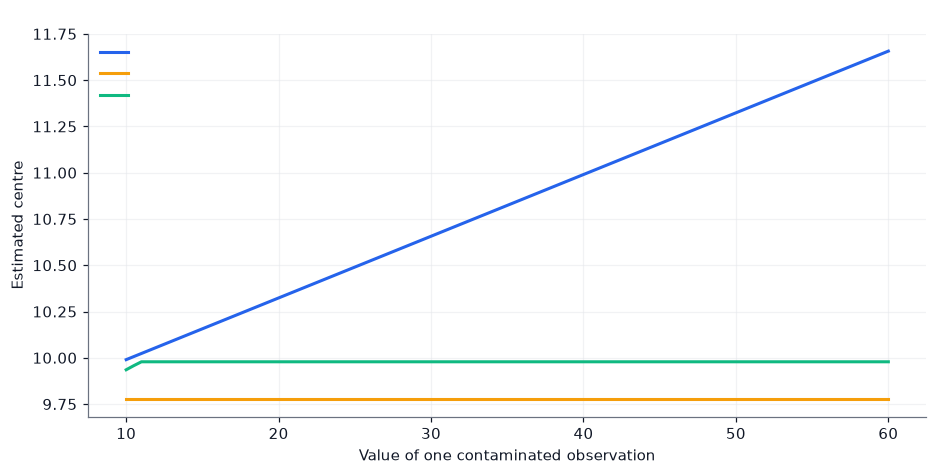

With the outlier at 60:  mean=11.66, median=9.78, Huber=9.98  (clean mean = 10.06)


In [13]:
def huber_location(values, delta=1.0, iterations=100):
    """Huber M-estimate of location by iteratively reweighted averaging."""
    mu = np.median(values)
    for _ in range(iterations):
        residual = values - mu
        weights = np.where(np.abs(residual) <= delta, 1.0, delta / np.maximum(np.abs(residual), 1e-12))
        mu = np.sum(weights * values) / np.sum(weights)
    return mu

rng_demo = np.random.default_rng(3)
clean_sample = rng_demo.normal(10.0, 1.0, size=30)
outlier_values = np.linspace(10, 60, 101)

means, medians, hubers = [], [], []
for outlier in outlier_values:
    sample = clean_sample.copy(); sample[0] = outlier
    means.append(sample.mean()); medians.append(np.median(sample)); hubers.append(huber_location(sample, 1.0))

fig, ax = plt.subplots(figsize=(8.6, 4.4))
ax.plot(outlier_values, means, color=COLORS["blue"], label="Mean (MSE)")
ax.plot(outlier_values, medians, color=COLORS["orange"], label="Median (MAE)")
ax.plot(outlier_values, hubers, color=COLORS["green"], label=r"Huber estimate ($\delta=1$)")
ax.set_xlabel("Value of one contaminated observation"); ax.set_ylabel("Estimated centre")
ax.set_title("One outlier drags the mean away; median and Huber barely move")
ax.legend(loc="upper left")
finish(fig, "05_robust_location")
print(f"With the outlier at 60:  mean={means[-1]:.2f}, median={medians[-1]:.2f}, Huber={hubers[-1]:.2f}  (clean mean = {clean_sample.mean():.2f})")

## 9. Mathematics III: linear regression, a `Dense(1)` layer, and the role of feature scaling

### 9.1 The normal equation

A linear model predicts $\hat{y} = Zw$, where $Z \in \mathbb{R}^{N \times (F+1)}$ is the design matrix (features plus a column of ones for the intercept) and $w$ the coefficient vector. The mean squared error is

$$
L(w) = \frac{1}{N}\,\lVert Zw - y \rVert^2 .
$$

Setting the gradient to zero,

$$
\nabla_w L = \frac{2}{N} Z^{\top}(Zw - y) = 0
\quad\Longrightarrow\quad
Z^{\top}Z\,w = Z^{\top}y
\quad\Longrightarrow\quad
w^{*} = (Z^{\top}Z)^{-1} Z^{\top} y .
$$

This **normal equation** has a closed-form solution when $Z^{\top}Z$ is invertible. For one-hot encoded categorical features, the intercept column equals the sum of the dummy columns (the *dummy-variable trap*), so one category must be dropped in an ordinary least-squares design. In NumPy, `np.linalg.lstsq` solves the problem in a numerically stable way.

### 9.2 A `Dense(1)` layer *is* linear regression

A Keras layer `Dense(1)` computes $\hat{y} = xW + b$, which is exactly $Zw$ with $w = (b, W)$. Trained with MSE, it minimizes the same $L(w)$ — by gradient descent instead of the closed form. A neural network with hidden layers adds nonlinearity on top of this; with no hidden layer, it collapses to linear regression. We verify this in Section 11.

### 9.3 Gradient descent on a quadratic: conditioning

The Hessian of $L(w)$ is constant:

$$
H = \frac{2}{N} Z^{\top} Z .
$$

Let $\lambda_{\max}$ and $\lambda_{\min}$ be its largest and smallest eigenvalues. The **condition number** is $\kappa = \lambda_{\max} / \lambda_{\min}$. Gradient descent with step size $\eta$ updates the error $e_t = w_t - w^{*}$ as

$$
e_{t+1} = (I - \eta H)\, e_t .
$$

In the eigenbasis of $H$, each component is multiplied at every step by $(1 - \eta \lambda_i)$. Stability requires $\eta \le 2/\lambda_{\max}$; with the common choice $\eta = 1/\lambda_{\max}$, the slowest direction contracts only by the factor

$$
1 - \frac{\lambda_{\min}}{\lambda_{\max}} = 1 - \frac{1}{\kappa},
\qquad\text{so about}\quad \kappa \ln\frac{1}{\varepsilon}\ \text{iterations are needed to reduce the error by } \varepsilon .
$$

> **A large condition number means very slow convergence along the flat directions of the loss surface.** Feature scaling changes $Z$, so it changes $H$ and $\kappa$.

Two different causes of a large $\kappa$:

1. **Different scales** of the columns (e.g. one feature in $[0, 1000]$, another in $[0, 0.01]$). Standardization fixes this.
2. **Collinearity** (nearly redundant columns). Standardization does *not* fix this; regularization or decorrelation methods are needed (Notebook 06 and later).

Let us measure both effects on the training data.

In [14]:
# Design matrices for the 7 continuous features: raw values vs standardized values (training statistics).
cont_train = X_train[:, :7].astype(float)
mu_c, sd_c = cont_train.mean(axis=0), cont_train.std(axis=0)

Z_raw = np.column_stack([np.ones(len(cont_train)), cont_train])
Z_std = np.column_stack([np.ones(len(cont_train)), (cont_train - mu_c) / sd_c])

def hessian_eigenvalues(Z):
    return np.linalg.eigvalsh((2.0 / len(Z)) * Z.T @ Z)

eig_raw, eig_std = hessian_eigenvalues(Z_raw), hessian_eigenvalues(Z_std)
kappa_raw, kappa_std = eig_raw.max() / eig_raw.min(), eig_std.max() / eig_std.min()
print(f"Condition number, raw features         : {kappa_raw:,.0f}")
print(f"Condition number, standardized features: {kappa_std:,.0f}")
print(f"Improvement from standardization       : {kappa_raw / kappa_std:,.1f}x")
print("\nEigenvalues (standardized):", np.round(np.sort(eig_std)[::-1], 3))

Condition number, raw features         : 18,398
Condition number, standardized features: 979
Improvement from standardization       : 18.8x

Eigenvalues (standardized): [12.623  2.     0.62   0.352  0.238  0.132  0.024  0.013]


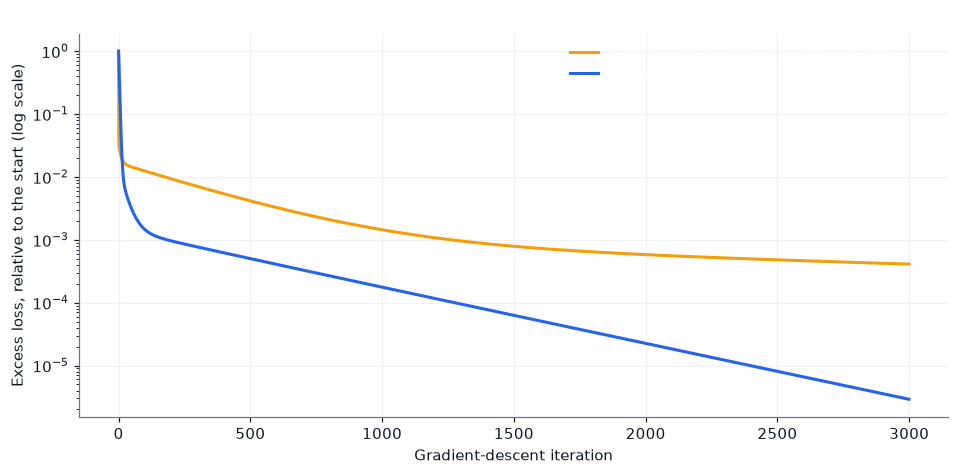

Excess loss after 3000 iterations (fraction of the initial gap):  raw = 4.11e-04,  standardized = 2.91e-06


In [15]:
# Full-batch gradient descent on the linear least-squares problem, with step size 1/lambda_max.
def gradient_descent_gap(Z, target, iterations=3000):
    n = len(Z)
    w_star = np.linalg.lstsq(Z, target, rcond=None)[0]
    optimum = np.mean((Z @ w_star - target) ** 2)
    lam_max = hessian_eigenvalues(Z).max()
    w = np.zeros(Z.shape[1]); gaps = []
    for _ in range(iterations):
        gaps.append(np.mean((Z @ w - target) ** 2) - optimum)
        w = w - (1.0 / lam_max) * (2.0 / n) * Z.T @ (Z @ w - target)
    return np.array(gaps)

target_train = y_train.astype(float)
gap_raw = gradient_descent_gap(Z_raw, target_train)
gap_std = gradient_descent_gap(Z_std, target_train)

fig, ax = plt.subplots(figsize=(8.8, 4.4))
ax.semilogy(gap_raw / gap_raw[0], color=COLORS["orange"], label=f"Raw features (condition number {kappa_raw:,.0f})")
ax.semilogy(gap_std / gap_std[0], color=COLORS["blue"], label=f"Standardized features (condition number {kappa_std:,.0f})")
ax.set_xlabel("Gradient-descent iteration"); ax.set_ylabel("Excess loss, relative to the start (log scale)")
ax.set_title("Standardization speeds up gradient descent — collinearity still limits it")
ax.legend(loc="upper right")
finish(fig, "06_conditioning")
print(f"Excess loss after 3000 iterations (fraction of the initial gap):  raw = {gap_raw[-1] / gap_raw[0]:.2e},  standardized = {gap_std[-1] / gap_std[0]:.2e}")

Standardization improves the conditioning, and gradient descent converges much faster. The condition number of the standardized problem is still far above 1 because the features are strongly collinear — the flat direction corresponds to combinations such as "difference between two nearly identical weights". That is exactly the direction in which coefficients are poorly determined. This is why we include a `Normalization` layer in every model, and why regularization (Notebook 06) matters for such data.

## 10. Reference models: the mean and ordinary least squares

Before training a neural network, we establish what *simple* models achieve. Any network must be judged against them.

1. **Mean predictor:** always predict the mean age of the training animals. It uses no feature. By construction, its $R^2$ on training data is zero.
2. **Ordinary least squares (OLS):** the linear regression of Section 9, computed in closed form on the standardized continuous features plus the sex dummies (with `F` as the reference category to avoid the dummy-variable trap).

We define regression metrics first (their definitions are in Section 13; here we only use the functions).

In [16]:
def regression_metrics(y_true, y_pred):
    """RMSE, MAE, median absolute error, R^2, and the fraction of predictions within 1 and 2 years."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    error = y_pred - y_true
    ss_res = np.sum(error ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return {"rmse": float(np.sqrt(np.mean(error ** 2))),
            "mae": float(np.mean(np.abs(error))),
            "medae": float(np.median(np.abs(error))),
            "r2": float(1.0 - ss_res / ss_tot),
            "within_1": float(np.mean(np.abs(error) <= 1.0)),
            "within_2": float(np.mean(np.abs(error) <= 2.0))}

# ---- Baseline 1: the training mean.
train_mean_age = float(y_train.mean())
predict_mean = lambda features: np.full(len(features), train_mean_age)

# ---- Baseline 2: OLS (closed form). Column order of X: 7 continuous, sex_F, sex_I, sex_M.
def ols_design(features):
    return np.column_stack([np.ones(len(features)), (features[:, :7] - mu_c) / sd_c,
                            features[:, 8], features[:, 9]])          # F is the reference category

w_ols = np.linalg.lstsq(ols_design(X_train), y_train.astype(float), rcond=None)[0]
predict_ols = lambda features: ols_design(features) @ w_ols

baseline_table = pd.DataFrame({
    "Mean predictor": regression_metrics(y_val, predict_mean(X_val)),
    "OLS": regression_metrics(y_val, predict_ols(X_val)),
}).round(3)
print("Validation set")
display(baseline_table)

Validation set


,Mean predictor,OLS
rmse,3.193,2.196
mae,2.356,1.571
medae,1.928,1.126
r2,-0.000,0.527
within_1,0.316,0.449
within_2,0.569,0.741


The mean predictor has $R^2 \approx 0$ (slightly negative when the validation mean differs from the training mean), and its RMSE equals the standard deviation of the target. OLS shows how much of the variance a **linear** combination of the measurements explains. The question for the neural network is: *does nonlinearity add anything beyond this?*

## 11. Designing the regression network

The input has 10 columns (7 continuous measurements and 3 one-hot sex columns). The output is **one real number**: the predicted age.

| Layer | Output shape | Parameters | Role |
|---|---|---|---|
| Input | `(None, 10)` | 0 | measurements and sex |
| Normalization | `(None, 10)` | 0 trainable | standardization using **training** statistics |
| Dense(64, ReLU) | `(None, 64)` | $10 \cdot 64 + 64 = 704$ | feature combinations |
| Dense(32, ReLU) | `(None, 32)` | $64 \cdot 32 + 32 = 2080$ | higher-level combinations |
| Dense(1), **linear** | `(None, 1)` | $32 \cdot 1 + 1 = 33$ | predicted age (unbounded real number) |

Total trainable parameters: $704 + 2080 + 33 = 2817$.

**Design choices specific to regression.**

- **No activation on the output.** A ReLU or sigmoid would restrict the range of predictions. (If the target had to be positive, a softplus or an exponential output would be an option.)
- **Output bias initialized to the training mean.** At the start of training, the network then predicts the mean age for every animal, so training begins from the mean-predictor baseline instead of wasting epochs learning the scale of the target.
- **Standardization of the inputs** is part of the model (Section 9.3 explains why it matters).
- The one-hot sex columns are standardized together with the other features. This is harmless: standardizing a binary column only shifts and scales it.

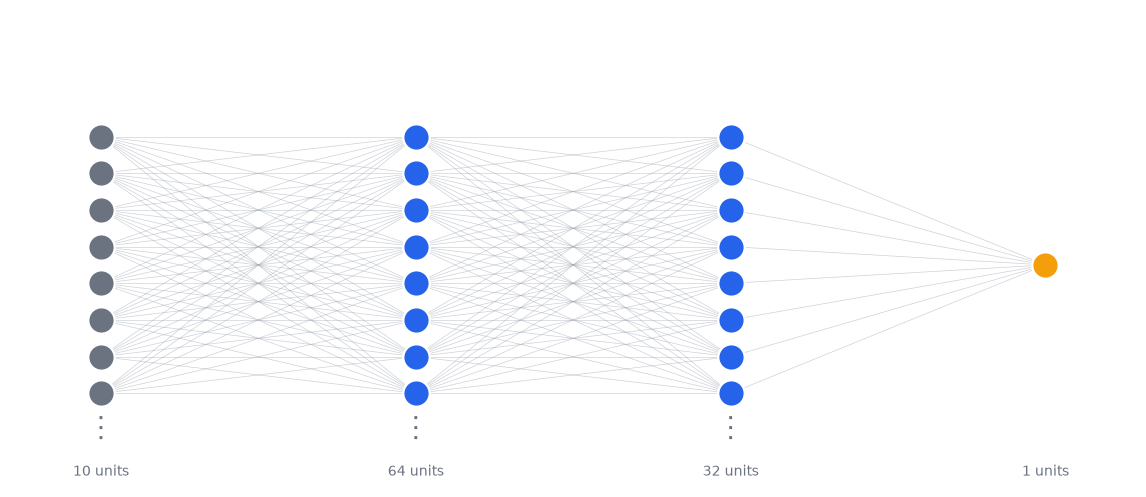

In [17]:
def draw_mlp(layer_sizes, layer_names, max_nodes=8):
    """Draw a schematic of a fully connected network (long layers are shown truncated)."""
    n_layers = len(layer_sizes)
    xs = np.linspace(0.08, 0.92, n_layers)
    layer_colors = [COLORS["gray"]] + [COLORS["blue"]] * (n_layers - 2) + [COLORS["orange"]]
    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    positions = []
    for i, size in enumerate(layer_sizes):
        shown = min(size, max_nodes)
        ys = np.linspace(0.14, 0.86, shown) if shown > 1 else np.array([0.5])
        positions.append([(xs[i], y_) for y_ in ys])
    for i in range(n_layers - 1):
        for (x0, y0) in positions[i]:
            for (x1, y1) in positions[i + 1]:
                ax.plot([x0, x1], [y0, y1], color="#9CA3AF", linewidth=0.45, alpha=0.5, zorder=1)
    for i, pts in enumerate(positions):
        for (px, py) in pts:
            ax.scatter(px, py, s=300, color=layer_colors[i], edgecolor="white", linewidth=1.5, zorder=3)
        if layer_sizes[i] > max_nodes:
            ax.text(xs[i], 0.04, "\u22ee", ha="center", va="center", fontsize=18, color=COLORS["gray"])
        ax.text(xs[i], 1.0, layer_names[i], ha="center", va="bottom", fontsize=10, fontweight="bold")
        ax.text(xs[i], -0.06, f"{layer_sizes[i]} units", ha="center", va="top", fontsize=9, color=COLORS["gray"])
    ax.set_xlim(0, 1); ax.set_ylim(-0.12, 1.08); ax.set_axis_off()
    ax.set_title("Regression MLP: a single linear output unit", loc="left", pad=22)
    return fig

fig = draw_mlp([10, 64, 32, 1], ["Input\n(10 features)", "Dense + ReLU", "Dense + ReLU", "Dense, linear\n(age in years)"])
finish(fig, "07_regression_mlp")

In [18]:
def build_regressor(hidden_units=(64, 32), name="abalone_mlp"):
    """Fresh, untrained regressor. Normalization statistics come from the TRAINING set only;
    the output bias starts at the training mean so that the initial prediction is the baseline."""
    normalization = keras.layers.Normalization(axis=-1, name="normalize_features")
    normalization.adapt(X_train)
    layers = [keras.layers.Input(shape=(n_features,), name="features"), normalization]
    for i, units in enumerate(hidden_units, start=1):
        layers.append(keras.layers.Dense(units, activation="relu", name=f"hidden_{i}"))
    layers.append(keras.layers.Dense(1, name="age_years",
                                     bias_initializer=keras.initializers.Constant(float(y_train.mean()))))
    return keras.Sequential(layers, name=name)

def count_trainable(model):
    return sum(int(np.prod(w.shape)) for w in model.trainable_weights)

preview = build_regressor()
preview.summary()
assert count_trainable(preview) == (10 * 64 + 64) + (64 * 32 + 32) + (32 * 1 + 1) == 2817
print("Trainable parameters:", count_trainable(preview))

Model: "abalone_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize_features              │ (None, 10)             │            21 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ age_years (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,838 (11.09 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 21 (88.00 B)

Trainable parameters: 2817


## 12. Regression metrics

Let $e_i = \hat{y}_i - y_i$ be the error of sample $i$ and $\bar{y}$ the mean of the true values.

| Metric | Definition | Meaning |
|---|---|---|
| MAE | $\frac{1}{N}\sum_i \lvert e_i \rvert$ | average error in years |
| RMSE | $\sqrt{\frac{1}{N}\sum_i e_i^2}$ | like MAE but penalizes large errors more; same unit as the target |
| Median absolute error | $\operatorname{median}(\lvert e_i \rvert)$ | the typical error, insensitive to outliers |
| $R^2$ | $1 - \dfrac{\sum_i e_i^2}{\sum_i (y_i - \bar{y})^2}$ | fraction of the variance explained, relative to the mean predictor |
| Within-$k$ accuracy | $\frac{1}{N}\#\{i : \lvert e_i \rvert \le k\}$ | fraction of animals dated within $k$ years |

**Relations worth knowing.**

- $\text{RMSE} \ge \text{MAE}$ always (by the power-mean inequality), with equality only when all absolute errors are equal. A large gap between them signals the presence of a few large errors.
- $R^2 = 1 - \text{RMSE}^2 / \operatorname{Var}(y)$ when the variance in the denominator is computed on the same data. $R^2 = 0$ means "no better than predicting the mean"; $R^2 < 0$ means worse. A high $R^2$ does not prove that predictions are *useful* in absolute terms: always read RMSE and MAE in the units of the problem.
- MAPE (mean absolute percentage error) is tempting but unstable for targets near zero and asymmetric; we do not use it.

The functions are in Section 10 (`regression_metrics`). A quick numerical check of the definitions:

In [19]:
y_true_toy = np.array([10.0, 12.0, 8.0, 15.0])
y_pred_toy = np.array([11.0, 11.0, 9.0, 12.0])
m = regression_metrics(y_true_toy, y_pred_toy)
e = y_pred_toy - y_true_toy
print("errors:", e)
print("MAE  =", np.mean(np.abs(e)), "| function:", m["mae"])
print("RMSE = sqrt(mean(e^2)) =", round(float(np.sqrt(np.mean(e**2))), 4), "| function:", round(m["rmse"], 4))
ss_tot = np.sum((y_true_toy - y_true_toy.mean())**2)
print("R^2  = 1 - sum(e^2)/SS_tot =", round(1 - np.sum(e**2) / ss_tot, 4), "| function:", round(m["r2"], 4))
assert m["rmse"] >= m["mae"]

errors: [ 1. -1.  1. -3.]
MAE  = 1.5 | function: 1.5
RMSE = sqrt(mean(e^2)) = 1.7321 | function: 1.7321
R^2  = 1 - sum(e^2)/SS_tot = 0.5514 | function: 0.5514


## 13. Training the regression MLP with MSE

We compile with the Adam optimizer, the `mse` loss, and two metrics reported in the original units: `MeanAbsoluteError` and `RootMeanSquaredError`. For early stopping and learning-rate reduction we monitor the **validation MAE**, a metric common to all models we compare later (the loss functions differ between models, so their validation losses would not be comparable).

In [20]:
def train_regressor(name, hidden_units=(64, 32), loss="mse", learning_rate=1e-3, max_epochs=300,
                    early_stopping=True, batch_size=32, seed=SEED):
    """Train a fresh regressor and return (model, history)."""
    keras.utils.set_random_seed(seed)
    model = build_regressor(hidden_units, name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=loss,
        metrics=[keras.metrics.MeanAbsoluteError(name="mae"),
                 keras.metrics.RootMeanSquaredError(name="rmse")],
    )
    callbacks = []
    if early_stopping:
        callbacks = [
            keras.callbacks.EarlyStopping(monitor="val_mae", mode="min", patience=30, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_mae", mode="min", factor=0.5, patience=10, min_lr=1e-5),
        ]
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=max_epochs,
                        batch_size=batch_size, callbacks=callbacks, verbose=0)
    return model, history

def best_epoch_of(history, key="val_mae"):
    return int(np.argmin(history.history[key])) + 1

mlp_mse, history_mse = train_regressor("mlp_mse")
best_mse = best_epoch_of(history_mse)
print("Epochs run         :", len(history_mse.history["loss"]))
print("Best epoch         :", best_mse)
print("Best validation MAE:", round(min(history_mse.history["val_mae"]), 4), "years")

Epochs run         : 101
Best epoch         : 71
Best validation MAE: 1.4693 years


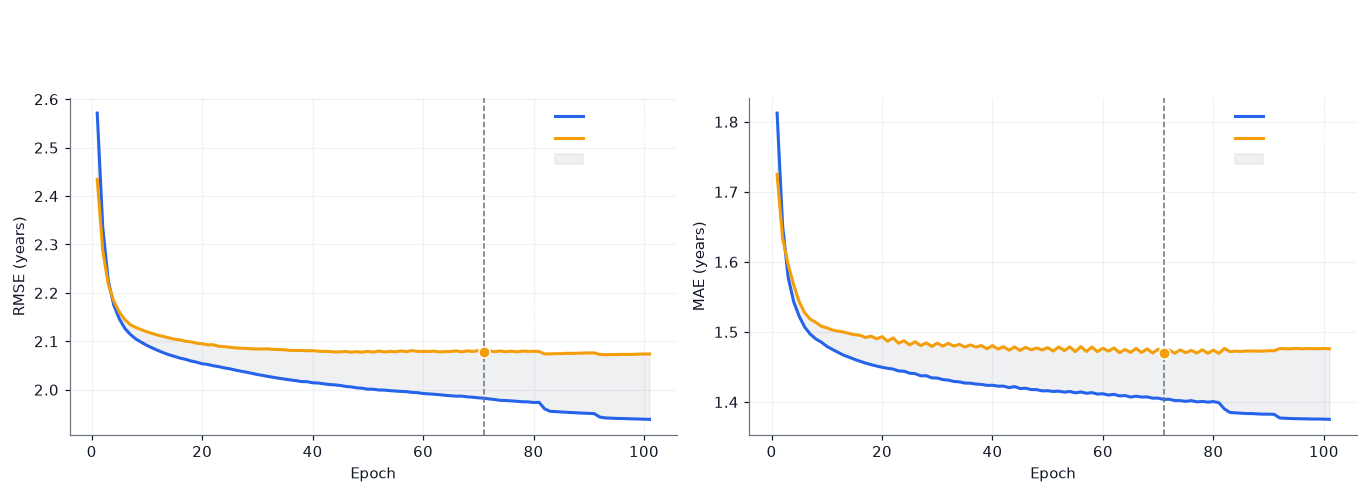

In [21]:
def plot_learning_curves(history, title, name, best_epoch=None):
    """RMSE and MAE learning curves with the generalization gap shaded and the best epoch marked."""
    h = history.history
    epochs = np.arange(1, len(h["rmse"]) + 1)
    if best_epoch is None:
        best_epoch = best_epoch_of(history)
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
    for ax, key, label in [(axes[0], "rmse", "RMSE (years)"), (axes[1], "mae", "MAE (years)")]:
        train_curve, val_curve = np.array(h[key]), np.array(h["val_" + key])
        ax.plot(epochs, train_curve, color=COLORS["blue"], label="Training")
        ax.plot(epochs, val_curve, color=COLORS["orange"], label="Validation")
        ax.fill_between(epochs, train_curve, val_curve, color=COLORS["gray"], alpha=0.10, label="Gap")
        ax.axvline(best_epoch, color=COLORS["gray"], linestyle="--", linewidth=1)
        ax.scatter([best_epoch], [val_curve[best_epoch - 1]], color=COLORS["orange"], s=55, zorder=5, edgecolor="white")
        ax.annotate(f"best epoch {best_epoch}\nvalidation = {val_curve[best_epoch - 1]:.2f}",
                    (best_epoch, val_curve[best_epoch - 1]), textcoords="offset points", xytext=(10, 14), fontsize=9)
        ax.set_xlabel("Epoch"); ax.set_ylabel(label); ax.set_title(label.split(" ")[0])
        ax.legend(loc="best")
    fig.suptitle(title, fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.03)
    finish(fig, name)

plot_learning_curves(history_mse, "MLP trained with MSE: learning curves", "08_mlp_mse_learning_curves", best_mse)

The training error keeps decreasing while the validation error flattens: the gap between the two curves is the beginning of overfitting. Because the target contains a large irreducible noise component (Section 7.1), the validation error cannot decrease below a floor, no matter how long we train.

### 13.1 Is a `Dense(1)` layer really linear regression?

We train a network with **no hidden layer** (just normalization and one `Dense(1)`) and compare its validation metrics with the closed-form OLS solution of Section 10. They should be close: both minimize the same convex least-squares problem.

In [22]:
# A "network" without hidden layers: Normalization -> Dense(1). Same minimization problem as OLS.
linear_keras, history_linear = train_regressor("linear_keras", hidden_units=(), learning_rate=1e-2, max_epochs=300)

predict_keras = lambda model: (lambda features: model.predict(features, verbose=0).ravel())
linear_metrics = regression_metrics(y_val, predict_keras(linear_keras)(X_val))
ols_metrics = regression_metrics(y_val, predict_ols(X_val))

comparison_linear = pd.DataFrame({"OLS (closed form)": ols_metrics, "Keras Dense(1), Adam": linear_metrics}).round(4)
display(comparison_linear)
print("Number of trainable parameters in the Keras linear model:", count_trainable(linear_keras), "(= 10 weights + 1 bias)")

,OLS (closed form),"Keras Dense(1), Adam"
rmse,2.1957,2.1969
mae,1.5711,1.5675
medae,1.1255,1.1202
r2,0.5271,0.5266
within_1,0.4489,0.4489
within_2,0.7412,0.7444


Number of trainable parameters in the Keras linear model: 11 (= 10 weights + 1 bias)


## 14. Evaluating on the validation set: predictions and residuals

We now study the predictions of the MLP in detail. All numbers in this section use the **validation** set; the test set stays untouched.

### 14.1 Does Keras compute the same numbers as our formulas?

In [23]:
val_pred_mse = predict_keras(mlp_mse)(X_val)
mlp_mse_val = regression_metrics(y_val, val_pred_mse)

keras_eval = mlp_mse.evaluate(X_val, y_val, verbose=0, return_dict=True)
print("Keras evaluate():   MAE =", round(keras_eval["mae"], 4), "| RMSE =", round(keras_eval["rmse"], 4))
print("Our NumPy formulas: MAE =", round(mlp_mse_val["mae"], 4), "| RMSE =", round(mlp_mse_val["rmse"], 4))
assert np.isclose(keras_eval["mae"], mlp_mse_val["mae"], atol=1e-3)
assert np.isclose(keras_eval["rmse"], mlp_mse_val["rmse"], atol=1e-3)

table_val = pd.DataFrame({
    "Mean predictor": regression_metrics(y_val, predict_mean(X_val)),
    "OLS": ols_metrics,
    "MLP (MSE)": mlp_mse_val,
}).round(3)
display(table_val)

Keras evaluate():   MAE = 1.4693 | RMSE = 2.0784
Our NumPy formulas: MAE = 1.4693 | RMSE = 2.0784


,Mean predictor,OLS,MLP (MSE)
rmse,3.193,2.196,2.078
mae,2.356,1.571,1.469
medae,1.928,1.126,0.980
r2,-0.000,0.527,0.576
within_1,0.316,0.449,0.508
within_2,0.569,0.741,0.773


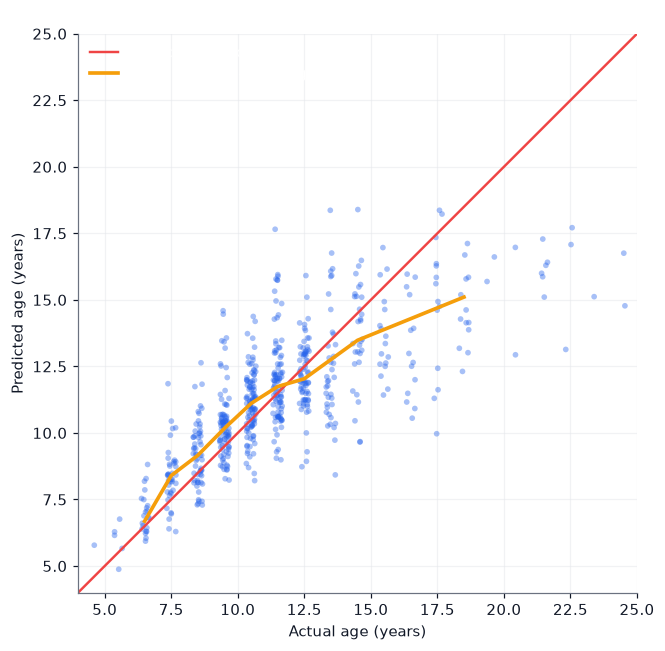

In [24]:
def plot_actual_vs_predicted(y_true, y_pred, title, name, band=None):
    """Predicted against actual age, with the identity line (and an optional +/- band)."""
    jitter = np.random.default_rng(0).uniform(-0.18, 0.18, size=len(y_true))   # true ages are discrete
    fig, ax = plt.subplots(figsize=(6.6, 6.0))
    low, high = min(y_true.min(), y_pred.min()) - 0.5, max(y_true.max(), y_pred.max()) + 0.5
    if band is not None:
        ax.fill_between([low, high], [low - band, high - band], [low + band, high + band],
                        color=COLORS["gray"], alpha=0.12, label=f"\u00b1 {band:.1f} years")
    ax.scatter(y_true + jitter, y_pred, s=14, alpha=0.40, color=COLORS["blue"], edgecolor="none")
    ax.plot([low, high], [low, high], color=COLORS["red"], linewidth=1.6, label="Perfect prediction")
    tx, ty = binned_trend(y_true, y_pred, n_bins=12)
    ax.plot(tx, ty, color=COLORS["orange"], linewidth=2.4, label="Median prediction per age")
    ax.set_xlim(low, high); ax.set_ylim(low, high); ax.set_aspect("equal")
    ax.set_xlabel("Actual age (years)"); ax.set_ylabel("Predicted age (years)"); ax.set_title(title)
    ax.legend(loc="upper left")
    finish(fig, name)

plot_actual_vs_predicted(y_val, val_pred_mse, "MLP (MSE): predicted against actual age (validation)", "09_actual_vs_predicted")

Look at the orange line (the median prediction for each true age). It is **flatter than the red diagonal**: young animals are predicted slightly too old, and old animals are predicted too young. This is **regression to the mean**: when the features carry only partial information about the target, the model's best guess shrinks towards the average. It is not a bug; it is exactly what minimizing squared error with noisy information produces (Section 7.1: the prediction estimates $\mathbb{E}[Y \mid X]$, and extreme values of $Y$ are, on average, less extreme than the extreme values of the evidence $X$).

### 14.2 Residual diagnostics

For a linear or nonlinear regression to be trusted, we examine the residuals $e_i = \hat{y}_i - y_i$.

1. **Residuals against predictions:** the spread should be roughly constant (*homoscedasticity*) and there should be no systematic curve. A fan shape means the error grows with the prediction (*heteroscedasticity*).
2. **Histogram of residuals:** is it symmetric? Are there heavy tails (outliers)?
3. **Q–Q plot:** quantiles of the standardized residuals against quantiles of the standard normal distribution. Points on the diagonal mean Gaussian-like residuals; departures at the ends mean heavy tails.

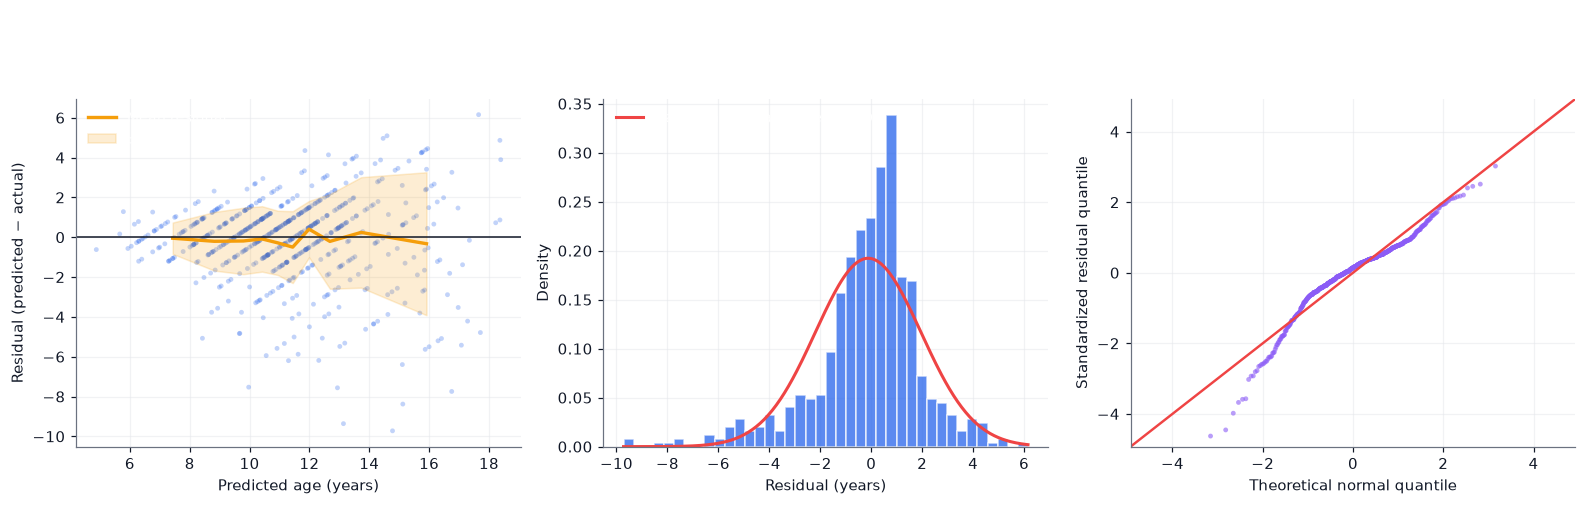

In [25]:
def plot_residual_diagnostics(y_true, y_pred, title, name):
    residual = y_pred - y_true
    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))

    # (1) residuals against predictions with a +/- 1 standard deviation band per quantile bin
    ax = axes[0]
    ax.scatter(y_pred, residual, s=10, alpha=0.28, color=COLORS["blue"], edgecolor="none")
    n_bins = 10
    edges_ = np.quantile(y_pred, np.linspace(0, 1, n_bins + 1))
    which = np.clip(np.digitize(y_pred, edges_[1:-1]), 0, n_bins - 1)
    centers = np.array([np.median(y_pred[which == b]) for b in range(n_bins)])
    means_ = np.array([residual[which == b].mean() for b in range(n_bins)])
    stds_ = np.array([residual[which == b].std() for b in range(n_bins)])
    ax.plot(centers, means_, color=COLORS["orange"], linewidth=2.2, label="Mean residual")
    ax.fill_between(centers, means_ - stds_, means_ + stds_, color=COLORS["orange"], alpha=0.18, label="\u00b1 1 SD")
    ax.axhline(0, color=COLORS["dark"], linewidth=1)
    ax.set_xlabel("Predicted age (years)"); ax.set_ylabel("Residual (predicted \u2212 actual)")
    ax.set_title("Residuals against predictions"); ax.legend(loc="upper left")

    # (2) histogram with the Gaussian density that has the same mean and standard deviation
    ax = axes[1]
    ax.hist(residual, bins=40, density=True, color=COLORS["blue"], alpha=0.75, edgecolor="white")
    grid = np.linspace(residual.min(), residual.max(), 300)
    ax.plot(grid, np.exp(-0.5 * ((grid - residual.mean()) / residual.std()) ** 2) / (residual.std() * np.sqrt(2 * np.pi)),
            color=COLORS["red"], linewidth=2, label="Gaussian with same mean / SD")
    ax.set_xlabel("Residual (years)"); ax.set_ylabel("Density"); ax.set_title("Distribution of residuals"); ax.legend()

    # (3) normal Q-Q plot
    ax = axes[2]
    sorted_res = np.sort((residual - residual.mean()) / residual.std())
    n = len(sorted_res)
    theoretical = np.array([NormalDist().inv_cdf((i - 0.5) / n) for i in range(1, n + 1)])
    ax.scatter(theoretical, sorted_res, s=10, alpha=0.6, color=COLORS["purple"], edgecolor="none")
    lim = max(abs(theoretical).max(), abs(sorted_res).max()) + 0.3
    ax.plot([-lim, lim], [-lim, lim], color=COLORS["red"], linewidth=1.6)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xlabel("Theoretical normal quantile"); ax.set_ylabel("Standardized residual quantile"); ax.set_title("Normal Q\u2013Q plot")

    fig.suptitle(title, fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.03)
    finish(fig, name)

plot_residual_diagnostics(y_val, val_pred_mse, "MLP (MSE): residual diagnostics on the validation set", "10_residual_diagnostics")

What to look for (compare with your own plots):

- In the first panel, the spread of residuals typically **increases with the predicted age**: errors are larger for old animals. This is heteroscedasticity, and it means a single "plus or minus" number cannot describe the uncertainty for every animal equally well (we return to this in Section 18).
- In the Q–Q plot, a curve leaving the diagonal at the upper end indicates a heavier right tail than a Gaussian: a few animals are much older than predicted. This is the situation where a **robust loss** such as Huber may help.

## 15. Training with the Huber loss

We choose $\delta$ following Section 8.1: estimate the noise scale robustly from the residuals of the OLS baseline **on the training set**, with the MAD, and set $\delta = 1.345\,\hat{\sigma}$.

In [26]:
train_residuals = predict_ols(X_train) - y_train
mad = np.median(np.abs(train_residuals - np.median(train_residuals)))
sigma_hat = 1.4826 * mad
delta = float(1.345 * sigma_hat)
print(f"Robust noise scale (MAD-based): {sigma_hat:.3f} years")
print(f"Huber delta = 1.345 * sigma     : {delta:.3f} years")
print(f"Ordinary standard deviation of the OLS residuals: {train_residuals.std():.3f} years (larger if there are heavy tails)")

Robust noise scale (MAD-based): 1.586 years
Huber delta = 1.345 * sigma     : 2.133 years
Ordinary standard deviation of the OLS residuals: 2.187 years (larger if there are heavy tails)


In [27]:
mlp_huber, history_huber = train_regressor("mlp_huber", loss=keras.losses.Huber(delta=delta))
best_huber = best_epoch_of(history_huber)
print("Epochs run         :", len(history_huber.history["loss"]))
print("Best epoch         :", best_huber)
print("Best validation MAE:", round(min(history_huber.history["val_mae"]), 4), "years")

val_pred_huber = predict_keras(mlp_huber)(X_val)
mlp_huber_val = regression_metrics(y_val, val_pred_huber)

table_val = pd.DataFrame({
    "Mean predictor": regression_metrics(y_val, predict_mean(X_val)),
    "OLS": ols_metrics,
    "MLP (MSE)": mlp_mse_val,
    "MLP (Huber)": mlp_huber_val,
}).round(3)
display(table_val)

Epochs run         : 157
Best epoch         : 127
Best validation MAE: 1.4444 years


,Mean predictor,OLS,MLP (MSE),MLP (Huber)
rmse,3.193,2.196,2.078,2.077
mae,2.356,1.571,1.469,1.444
medae,1.928,1.126,0.980,0.938
r2,-0.000,0.527,0.576,0.577
within_1,0.316,0.449,0.508,0.519
within_2,0.569,0.741,0.773,0.762


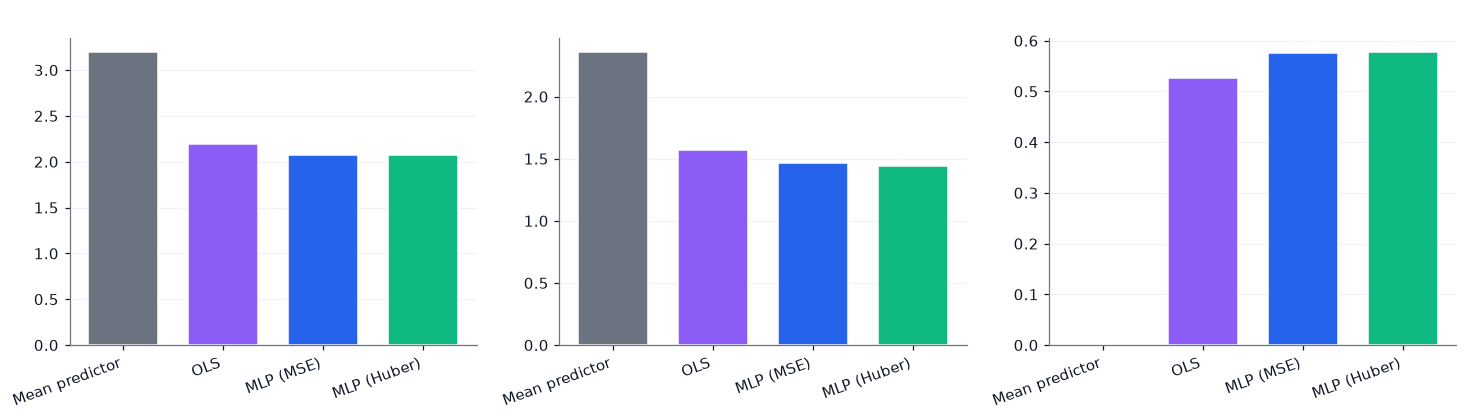

In [28]:
# Figure: validation metrics of all models, side by side.
models_val = ["Mean predictor", "OLS", "MLP (MSE)", "MLP (Huber)"]
bar_colors = [COLORS["gray"], COLORS["purple"], COLORS["blue"], COLORS["green"]]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
for ax, metric, label, lower_is_better in [(axes[0], "rmse", "RMSE (years)", True),
                                           (axes[1], "mae", "MAE (years)", True),
                                           (axes[2], "r2", "$R^2$", False)]:
    values = [table_val.loc[metric, m] for m in models_val]
    bars = ax.bar(models_val, values, color=bar_colors, edgecolor="white", width=0.7)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, max(value, 0) + 0.01 * max(values), f"{value:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(label + ("  (lower is better)" if lower_is_better else "  (higher is better)"))
    ax.set_xticks(range(len(models_val))); ax.set_xticklabels(models_val, rotation=20, ha="right")
    ax.grid(axis="x", visible=False)
finish(fig, "11_model_comparison_validation")

Compare the models carefully. With one training run each and about 600 validation animals, differences of a few hundredths of a year in MAE or RMSE are within random variation (we quantify this in Section 17). A strong result would be a **consistent** improvement over OLS across metrics; a weak or inconsistent one suggests that, for these features, most of what can be learned is already captured by a linear model — a legitimate and common finding.

The Huber model optimizes a different objective: it tends to improve **MAE** (typical error) more than RMSE, and it may trade a little RMSE for robustness. Neither choice is universally right; it depends on whether large errors are especially costly.

## 16. Underfitting and overfitting

### 16.1 The bias–variance decomposition

For a fixed input $x$, consider the prediction $\hat{f}(x)$ of a model trained on a random training sample. The expected squared error decomposes as

$$
\mathbb{E}\big[(Y - \hat{f}(x))^2\big]
= \underbrace{\sigma^2}_{\text{noise}}
+ \underbrace{\big(\mathbb{E}[\hat{f}(x)] - \mu(x)\big)^2}_{\text{bias}^2}
+ \underbrace{\operatorname{Var}\big(\hat{f}(x)\big)}_{\text{variance}} ,
$$

where $\mu(x) = \mathbb{E}[Y \mid X = x]$.

- **Bias** is the systematic error of the model class: a model that is too simple cannot represent $\mu(x)$ (**underfitting**).
- **Variance** is the sensitivity to the particular training sample: a model that is too flexible fits noise in the sample (**overfitting**).
- **Noise** cannot be reduced by any model.

Increasing capacity typically decreases bias and increases variance. The best generalization lies in between.

### 16.2 Diagnosing from errors

| Pattern | Training error | Validation error | Diagnosis | Typical remedy |
|---|---|---|---|---|
| Both high and close together | high | high | underfitting (high bias) | more capacity, better features, longer training |
| Low training error, much higher validation error | low | high | overfitting (high variance) | more data, regularization, early stopping, smaller model |
| Both low and close | low | low | good fit (up to the noise floor) | — |

### 16.3 Experiment 1: a capacity sweep

We train networks of increasing size for a **fixed number of epochs without early stopping**, and compare the final training and validation RMSE. (This takes a few minutes on a CPU. Lower `SWEEP_EPOCHS` for a quicker run.)

In [29]:
SWEEP_EPOCHS = 100      # reduce (e.g. to 40) for a quicker run
sweep_configs = [(2,), (4,), (8,), (16,), (32, 32), (64, 64, 32), (128, 128, 128)]

sweep_rows = []
for hidden in sweep_configs:
    model_s, history_s = train_regressor(f"sweep_{'x'.join(map(str, hidden))}", hidden_units=hidden,
                                         max_epochs=SWEEP_EPOCHS, early_stopping=False)
    train_pred = predict_keras(model_s)(X_train)
    val_pred_s = predict_keras(model_s)(X_val)
    sweep_rows.append({
        "hidden units": str(hidden),
        "trainable parameters": count_trainable(model_s),
        "train RMSE": regression_metrics(y_train, train_pred)["rmse"],
        "validation RMSE": regression_metrics(y_val, val_pred_s)["rmse"],
        "best val RMSE during training": float(np.min(history_s.history["val_rmse"])),
    })
sweep = pd.DataFrame(sweep_rows)
display(sweep.round(3))

,hidden units,trainable parameters,train RMSE,validation RMSE,best val RMSE during training
0,"(2,)",25,2.196,2.191,2.191
1,"(4,)",49,2.081,2.104,2.104
2,"(8,)",97,2.060,2.096,2.096
3,"(16,)",193,2.052,2.090,2.090
4,"(32, 32)",1441,1.954,2.046,2.045
5,"(64, 64, 32)",6977,1.787,2.165,2.043
6,"(128, 128, 128)",34561,1.494,2.488,2.074


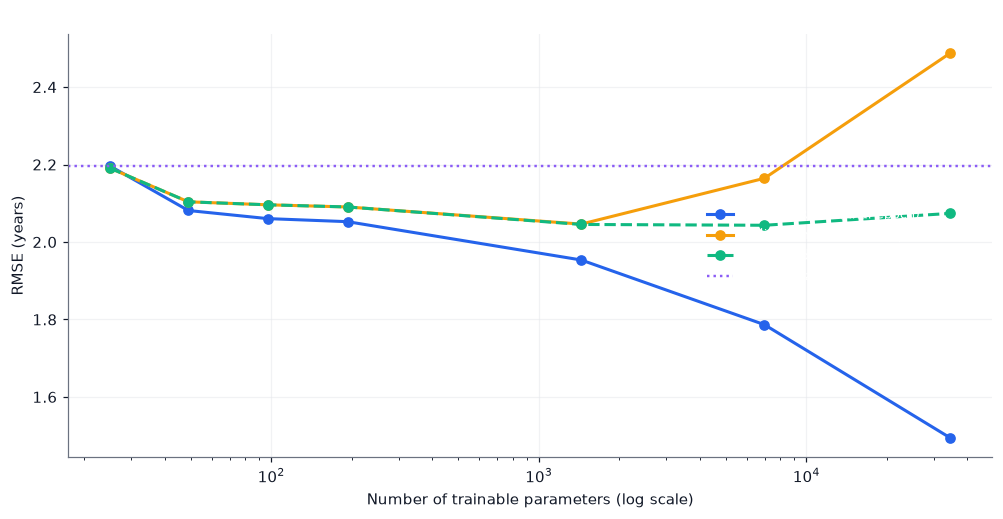

In [30]:
fig, ax = plt.subplots(figsize=(9.2, 4.8))
ax.plot(sweep["trainable parameters"], sweep["train RMSE"], marker="o", color=COLORS["blue"], label="Training RMSE (final epoch)")
ax.plot(sweep["trainable parameters"], sweep["validation RMSE"], marker="o", color=COLORS["orange"], label="Validation RMSE (final epoch)")
ax.plot(sweep["trainable parameters"], sweep["best val RMSE during training"], marker="o", linestyle="--",
        color=COLORS["green"], label="Best validation RMSE during training")
ax.axhline(ols_metrics["rmse"], color=COLORS["purple"], linestyle=":", linewidth=1.6, label="OLS validation RMSE")
ax.set_xscale("log")
ax.set_xlabel("Number of trainable parameters (log scale)"); ax.set_ylabel("RMSE (years)")
ax.set_title("Capacity sweep: the gap between training and validation grows with capacity")
ax.legend(loc="center right", fontsize=8.5)
finish(fig, "12_capacity_sweep")

How to read the figure: the **training** error usually keeps decreasing as capacity grows, while the **validation** error stops improving and may rise. The gap between them measures overfitting. The green dashed curve shows what early stopping can recover: the best validation error reached *during* training is often better than the final-epoch error of large models. Note that all networks, regardless of size, remain limited by the noise floor $\sigma^2$.

### 16.4 Experiment 2: a large model trained for a long time without early stopping

We take the biggest network and train it for 300 epochs without any safeguard, then look at the learning curves.

Epoch with the lowest validation MAE: 19 of 300
Validation MAE at that epoch : 1.517
Validation MAE at the last epoch: 1.875
Training   MAE at the last epoch: 0.608


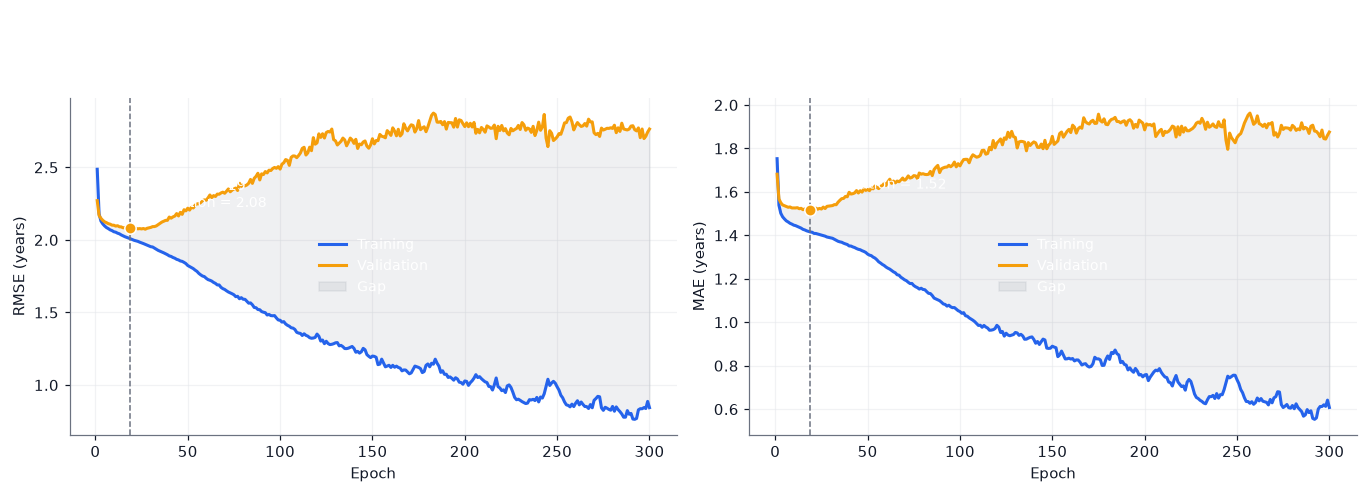

In [31]:
big_model, history_big = train_regressor("big_no_early_stopping", hidden_units=(128, 128, 128),
                                         max_epochs=300, early_stopping=False)
best_big = best_epoch_of(history_big)
print("Epoch with the lowest validation MAE:", best_big, "of 300")
print("Validation MAE at that epoch :", round(history_big.history["val_mae"][best_big - 1], 3))
print("Validation MAE at the last epoch:", round(history_big.history["val_mae"][-1], 3))
print("Training   MAE at the last epoch:", round(history_big.history["mae"][-1], 3))
plot_learning_curves(history_big, "A large network without early stopping: overfitting", "13_overfitting_demo", best_big)

Each additional epoch after the dashed line improves the training error but not the validation error: the network is learning idiosyncrasies of the training animals. **Early stopping** (used in all our other runs) selects the epoch at the dashed line automatically. More powerful remedies — Dropout, L1/L2 regularization, batch normalization — are the subject of Notebook 06.

## 17. Model selection and the final test evaluation

We compare three candidates with **one declared rule**, written down before looking at the test set:

> *Select the model with the lowest validation MAE. If the best neural network improves the MAE of OLS by less than 0.05 years, prefer the simpler model (OLS).*

The mean predictor is kept only as a reference. The rule is applied using **validation** results only; then the chosen model is evaluated on the test set **once**.

In [32]:
candidates = {
    "OLS": predict_ols,
    "MLP (MSE)": predict_keras(mlp_mse),
    "MLP (Huber)": predict_keras(mlp_huber),
}
validation_mae = {name: regression_metrics(y_val, fn(X_val))["mae"] for name, fn in candidates.items()}
print("Validation MAE:", {k: round(v, 4) for k, v in validation_mae.items()})

best_mlp_name = min(["MLP (MSE)", "MLP (Huber)"], key=lambda k: validation_mae[k])
if validation_mae["OLS"] - validation_mae[best_mlp_name] < 0.05:
    selected_name = "OLS"
else:
    selected_name = best_mlp_name
print("Best neural network:", best_mlp_name, "| improvement over OLS:", round(validation_mae["OLS"] - validation_mae[best_mlp_name], 4), "years")
print("Selected model     :", selected_name)

Validation MAE: {'OLS': 1.5711, 'MLP (MSE)': 1.4693, 'MLP (Huber)': 1.4444}
Best neural network: MLP (Huber) | improvement over OLS: 0.1267 years
Selected model     : MLP (Huber)


,Mean predictor,Selected: MLP (Huber)
rmse,3.288,2.198
mae,2.385,1.494
medae,1.928,1.019
r2,-0.000,0.553
within_1,0.316,0.489
within_2,0.569,0.768


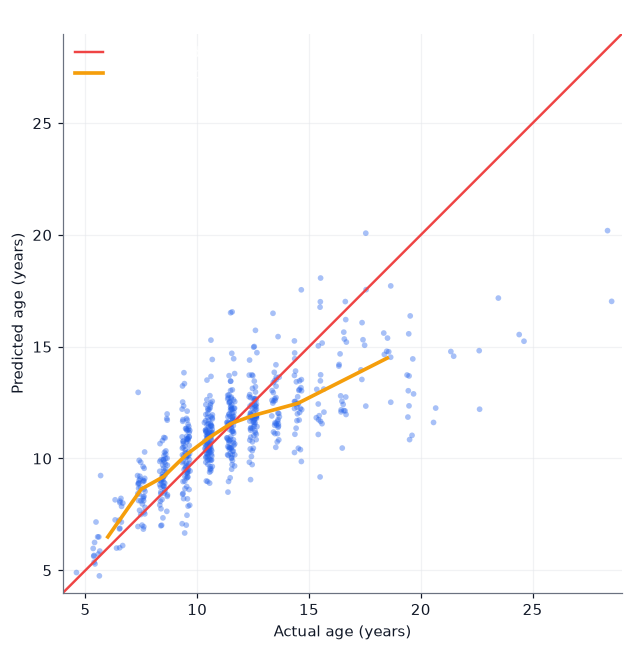

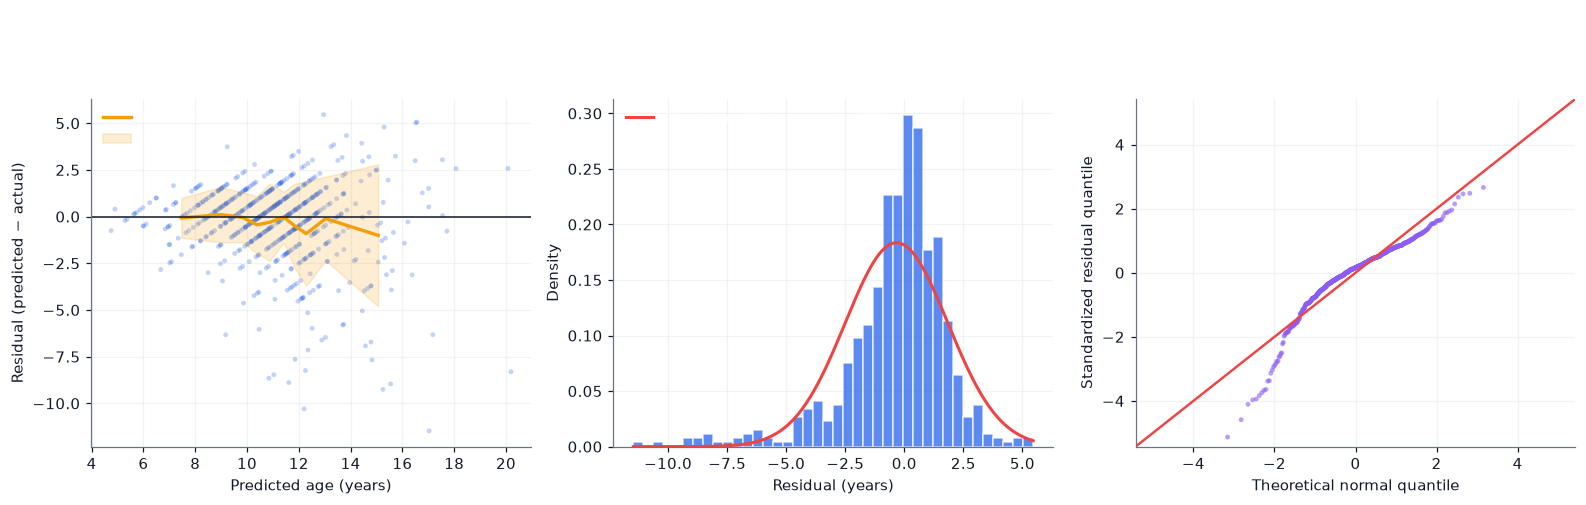

In [33]:
selected_predict = candidates[selected_name]
test_pred = selected_predict(X_test)
test_metrics = regression_metrics(y_test, test_pred)

# Reference values on the test set.
reference_table = pd.DataFrame({
    "Mean predictor": regression_metrics(y_test, predict_mean(X_test)),
    f"Selected: {selected_name}": test_metrics,
}).round(3)
display(reference_table)

plot_actual_vs_predicted(y_test, test_pred, f"{selected_name}: predicted against actual age (test)", "14_test_actual_vs_predicted")
plot_residual_diagnostics(y_test, test_pred, f"{selected_name}: residual diagnostics on the test set", "15_test_residual_diagnostics")

### 17.1 How uncertain is the test result? Bootstrap intervals

As in Notebook 04, we resample the test set with replacement and recompute the metrics $B = 2000$ times; the 2.5th and 97.5th percentiles give a 95% percentile interval.

We also compute a **paired bootstrap** for the *difference* between the selected model and the mean predictor (or, if the selected model is a neural network, OLS), using the **same resampled animals** for both models. A difference whose interval excludes zero is evidence of a real improvement on this test population; an interval that contains zero means the data cannot distinguish the models.

Test results for the selected model (MLP (Huber)), 95% bootstrap intervals
   RMSE: 2.198   [1.992, 2.400]
    MAE: 1.494   [1.376, 1.616]
    R^2: 0.553   [0.498, 0.603]

Paired difference in MAE (MLP (Huber) minus OLS): -0.131  [-0.196, -0.065]


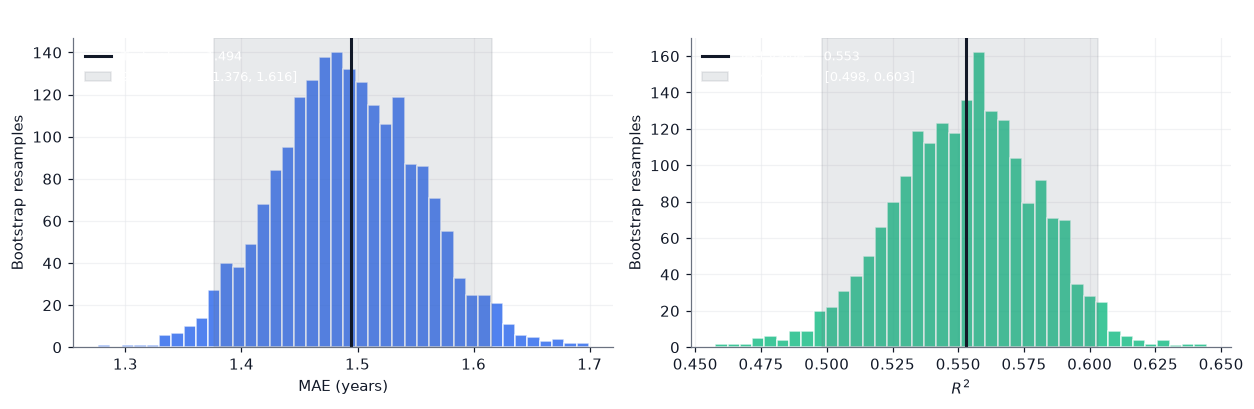

In [34]:
def bootstrap_regression(y_true, preds_dict, n_boot=2000, seed=0):
    """Paired bootstrap: the same resampled indices are used for every model in preds_dict."""
    resampler = np.random.default_rng(seed)
    n = len(y_true)
    results = {name: {"rmse": [], "mae": [], "r2": []} for name in preds_dict}
    for _ in range(n_boot):
        idx = resampler.integers(0, n, size=n)
        for name, pred in preds_dict.items():
            m = regression_metrics(y_true[idx], pred[idx])
            for key in ("rmse", "mae", "r2"):
                results[name][key].append(m[key])
    return {name: {k: np.array(v) for k, v in d.items()} for name, d in results.items()}

comparison_name = "OLS" if selected_name != "OLS" else "Mean predictor"
comparison_predict = candidates["OLS"] if selected_name != "OLS" else predict_mean
boot = bootstrap_regression(y_test, {selected_name: test_pred, comparison_name: comparison_predict(X_test)})

print(f"Test results for the selected model ({selected_name}), 95% bootstrap intervals")
for metric, label in [("rmse", "RMSE"), ("mae", "MAE"), ("r2", "R^2")]:
    low, high = np.percentile(boot[selected_name][metric], [2.5, 97.5])
    print(f"  {label:>5}: {test_metrics[metric]:.3f}   [{low:.3f}, {high:.3f}]")

diff_mae = boot[selected_name]["mae"] - boot[comparison_name]["mae"]
low, high = np.percentile(diff_mae, [2.5, 97.5])
print(f"\nPaired difference in MAE ({selected_name} minus {comparison_name}): {np.mean(diff_mae):+.3f}  [{low:+.3f}, {high:+.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, values, point, label, color in [
        (axes[0], boot[selected_name]["mae"], test_metrics["mae"], "MAE (years)", COLORS["blue"]),
        (axes[1], boot[selected_name]["r2"], test_metrics["r2"], "$R^2$", COLORS["green"])]:
    low_, high_ = np.percentile(values, [2.5, 97.5])
    ax.hist(values, bins=40, color=color, alpha=0.8, edgecolor="white")
    ax.axvline(point, color=COLORS["dark"], linewidth=2, label=f"Test value = {point:.3f}")
    ax.axvspan(low_, high_, color=COLORS["gray"], alpha=0.15, label=f"95% interval [{low_:.3f}, {high_:.3f}]")
    ax.set_xlabel(label); ax.set_ylabel("Bootstrap resamples"); ax.set_title(f"Bootstrap distribution: {label}")
    ax.legend(loc="upper left", fontsize=8.5)
finish(fig, "16_bootstrap_intervals")

## 18. Error analysis and prediction intervals

### 18.1 Where does the model make its errors?

An overall MAE can hide the fact that errors depend strongly on the animal's age. We group the test animals by **true age** and look at two quantities per group:

- the **mean residual** (bias): positive means the model over-estimates age in that group;
- the **MAE**.

Regression to the mean (Section 14.1) predicts positive bias for young animals and negative bias for old animals.

,true age (years),n,mean residual (bias),MAE
0,≤ 7,28,0.70,0.88
1,8–9,98,0.92,1.12
2,10–11,188,0.58,1.03
3,12–13,168,-0.15,1.01
4,14–16,88,-1.60,1.96
5,≥ 17,56,-4.62,4.73


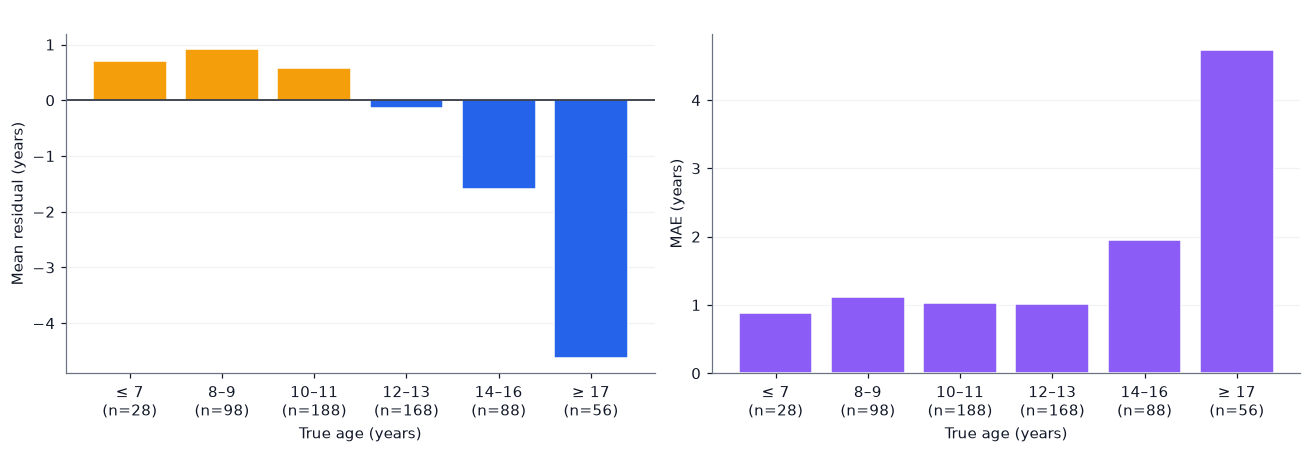

MAE by sex:


,n,MAE (years)
Female,190,1.985
Infant,189,1.043
Male,247,1.462


In [35]:
age_edges = [0, 7.5, 9.5, 11.5, 13.5, 16.5, 100]
age_labels = ["\u2264 7", "8\u20139", "10\u201311", "12\u201313", "14\u201316", "\u2265 17"]
group = np.digitize(y_test, age_edges[1:-1])
residual_test = test_pred - y_test

rows = []
for g, label in enumerate(age_labels):
    mask = group == g
    rows.append({"true age (years)": label, "n": int(mask.sum()),
                 "mean residual (bias)": residual_test[mask].mean() if mask.any() else np.nan,
                 "MAE": np.abs(residual_test[mask]).mean() if mask.any() else np.nan})
by_age = pd.DataFrame(rows)
display(by_age.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(by_age))
bias_colors = [COLORS["orange"] if v > 0 else COLORS["blue"] for v in by_age["mean residual (bias)"].fillna(0)]
axes[0].bar(x, by_age["mean residual (bias)"], color=bias_colors, edgecolor="white")
axes[0].axhline(0, color=COLORS["dark"], linewidth=1)
axes[0].set_title("Bias by true age group (orange: over-estimated, blue: under-estimated)")
axes[0].set_ylabel("Mean residual (years)")
axes[1].bar(x, by_age["MAE"], color=COLORS["purple"], edgecolor="white")
axes[1].set_title("MAE by true age group"); axes[1].set_ylabel("MAE (years)")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(by_age["true age (years)"], by_age["n"])])
    ax.set_xlabel("True age (years)"); ax.grid(axis="x", visible=False)
finish(fig, "17_error_by_age_group")

residual_sex = pd.DataFrame({"sex": sex_test, "abs_error": np.abs(residual_test)}).groupby("sex")["abs_error"].agg(["count", "mean"]).round(3)
residual_sex.index = [SEX_NAMES[s] for s in residual_sex.index]
print("MAE by sex:"); display(residual_sex.rename(columns={"count": "n", "mean": "MAE (years)"}))

### 18.2 Prediction intervals with split-conformal prediction

A point prediction alone says nothing about how reliable it is. **Split-conformal prediction** gives an interval with a *distribution-free* coverage guarantee, using held-out data:

1. Compute the absolute residuals $s_i = |y_i - \hat{y}_i|$ on a **calibration set** of $n$ animals that were not used for training.
2. Let $q$ be the $\lceil (n+1)(1-\alpha) \rceil / n$ quantile of the $s_i$.
3. For a new animal, report the interval $\hat{y} \pm q$.

If the calibration and new data are exchangeable, the interval contains the true age with probability **at least $1-\alpha$**. We use $\alpha = 0.10$ (90% intervals).

*Caveats.* (i) We use the validation set as the calibration set, although it was also used for model selection. A separate calibration set would be cleaner, and the guarantee is formally for a model chosen independently of the calibration data. (ii) The guarantee is **marginal** (averaged over all animals), and this interval has a **constant width**; because the errors are larger for old animals (Section 14.2), coverage is expected to be better for young than for old animals.

Calibration set size: 626 | quantile level: 0.9026 | interval half-width q = 3.49 years
Overall coverage on the test set: 0.906  (target at least 0.90)


,true age (years),n,coverage
0,≤ 7,28,0.964
1,8–9,98,0.990
2,10–11,188,0.973
3,12–13,168,0.988
4,14–16,88,0.875
5,≥ 17,56,0.304


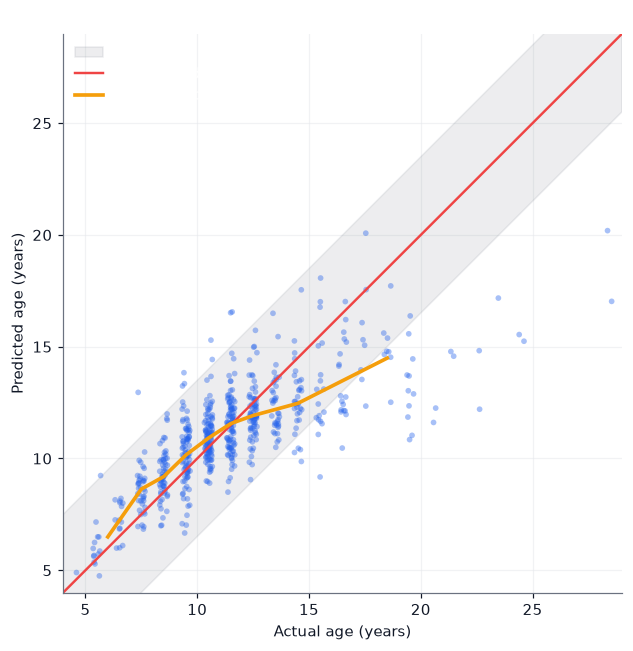

In [36]:
alpha = 0.10
calibration_scores = np.abs(y_val - selected_predict(X_val))
n_cal = len(calibration_scores)
level = min(1.0, math.ceil((n_cal + 1) * (1 - alpha)) / n_cal)
q = float(np.quantile(calibration_scores, level, method="higher"))
print(f"Calibration set size: {n_cal} | quantile level: {level:.4f} | interval half-width q = {q:.2f} years")

covered = np.abs(y_test - test_pred) <= q
print(f"Overall coverage on the test set: {covered.mean():.3f}  (target at least {1 - alpha:.2f})")

# Coverage by true age group: the guarantee is marginal, not conditional.
coverage_rows = []
for g, label in enumerate(age_labels):
    mask = group == g
    coverage_rows.append({"true age (years)": label, "n": int(mask.sum()),
                          "coverage": covered[mask].mean() if mask.any() else np.nan})
coverage_by_age = pd.DataFrame(coverage_rows)
display(coverage_by_age.round(3))

plot_actual_vs_predicted(y_test, test_pred, f"90% split-conformal band (\u00b1 {q:.1f} years), test set", "18_conformal_band", band=q)

The overall coverage should be close to or above 90%, but it is typically **lower for old animals and higher for young ones**: a constant-width interval is too narrow where the model is least certain and too wide where it is most certain. Methods that adapt the width to the input (for example, conformalized quantile regression) address this; they build on the ideas of this notebook and of Notebook 06.

## 19. What can and cannot be concluded

**What the results can support.** If the selected model reduces the error clearly below the mean predictor (and, for a neural network, also below OLS), then physical measurements contain useful information about age, and the model can provide an approximate age estimate, with an honest uncertainty interval, for animals that were not aged by ring counting.

**What the results do not support.**

1. *Age is not fully determined by these measurements.* A large irreducible error remains (Section 7.1). The model cannot replace ring counting when individual ages matter.
2. *Regression to the mean.* Old animals tend to be under-estimated and young ones over-estimated. Any use of the predictions for age *structure* of a population (for example, the proportion of old animals) will be biased unless this is corrected.
3. *Population shift.* All animals come from one species in one region (Tasmanian blacklip abalone) and one study. Growth depends on food, temperature, and location, so the relationship between size and age may differ elsewhere.
4. *Heteroscedastic errors.* Errors grow with age, so a single "average error" is not representative for every animal.
5. *One split, one run per model.* Model choices were made on a single validation set. Repeated runs or cross-validation (Notebook 07) would give more reliable comparisons.
6. *Sex as a feature.* The `I` (infant) category is a developmental stage, not a fixed property; its strong association with young age is expected by construction.

## 20. Saving the model with its metadata

As in Notebook 04, we store the model together with the information needed to use it correctly: feature order, one-hot column order, the selection decision, the chosen interval width, test metrics, and package versions. If the selected model is OLS, we store its coefficients instead of a Keras file.

In [37]:
metadata = {
    "dataset": "UCI Abalone (Nash et al., 1994), CC BY 4.0",
    "target": "age_years = rings + 1.5",
    "feature_order": FEATURES,
    "sex_onehot_columns": SEX_COLUMNS,
    "rows_removed_for_height_zero": int(len(df_raw) - len(df)),
    "selected_model": selected_name,
    "validation_mae": {k: float(v) for k, v in validation_mae.items()},
    "huber_delta": delta,
    "split_sizes": {"train": int(len(y_train)), "validation": int(len(y_val)), "test": int(len(y_test))},
    "seed": SEED,
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "conformal": {"alpha": alpha, "half_width_years": q, "test_coverage": float(covered.mean())},
    "versions": {"python": sys.version.split()[0], "keras": keras.__version__,
                 "backend": keras.backend.backend(), "numpy": np.__version__},
}
if selected_name == "OLS":
    metadata["ols"] = {"coefficients": [float(v) for v in w_ols], "continuous_means": [float(v) for v in mu_c],
                       "continuous_stds": [float(v) for v in sd_c],
                       "design": "intercept, 7 standardized continuous features, sex_I, sex_M (sex_F is the reference)"}
    print("Selected model is OLS; coefficients stored in the metadata file.")
else:
    model_path = os.path.join(ARTIFACT_DIR, "abalone_age_mlp.keras")
    {"MLP (MSE)": mlp_mse, "MLP (Huber)": mlp_huber}[selected_name].save(model_path)
    reloaded = keras.models.load_model(model_path)
    same = np.allclose(reloaded.predict(X_test[:20], verbose=0).ravel(), test_pred[:20], atol=1e-4)
    print("Reloaded predictions identical:", same)

with open(os.path.join(ARTIFACT_DIR, "abalone_age_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

# Using the model for one animal: raw features in, age (with a 90% interval) out.
animal = X_test[:1]
estimate = float(selected_predict(animal)[0])
print(f"\nExample animal: estimated age {estimate:.1f} years (90% interval {estimate - q:.1f} to {estimate + q:.1f}); true age {y_test[0]:.1f}")

Reloaded predictions identical: True

Example animal: estimated age 10.9 years (90% interval 7.4 to 14.4); true age 9.5


## 21. What did we learn?

1. A regression network ends in **one linear unit**; the loss is MSE, MAE, or Huber, and the metrics are in the units of the target.
2. Squared error estimates the **conditional mean**, absolute error the **conditional median**; these correspond to Gaussian and Laplace noise. The best achievable error is the **noise floor** $\sigma^2$.
3. **Huber loss** has a clipped gradient: robust to outliers like MAE, smooth like MSE. A robust choice of $\delta$ comes from the MAD.
4. `Dense(1)` trained with MSE is **linear regression**; its closed form is the normal equation. OLS is the reference model any neural network must beat.
5. The **condition number** governs the speed of gradient descent. Standardization improves it; collinearity limits it.
6. RMSE, MAE, median absolute error, $R^2$, and within-$k$ accuracy answer different questions, and RMSE $\ge$ MAE.
7. **Residual diagnostics** reveal heteroscedasticity, heavy tails, and **regression to the mean**.
8. **Underfitting** (high bias) and **overfitting** (high variance) show up as the gap between training and validation errors; capacity sweeps and learning curves make them visible.
9. **Bootstrap** and **split-conformal** methods quantify the uncertainty of a metric and of an individual prediction.

### Key terms

| Term | Meaning |
|---|---|
| Regression | Predicting a continuous target |
| Residual | $\hat{y} - y$ |
| MSE / MAE / Huber | Squared, absolute, and clipped-quadratic loss |
| Conditional mean / median | $\mathbb{E}[Y\mid X]$ / the 50% quantile of $Y \mid X$ |
| Irreducible noise | Variance of $Y$ not explained by any function of $X$ |
| Normal equation | $Z^{\top}Z\,w = Z^{\top}y$ |
| Condition number | $\lambda_{\max}/\lambda_{\min}$ of the Hessian |
| Collinearity | Nearly redundant features |
| $R^2$ | Fraction of variance explained relative to the mean predictor |
| Heteroscedasticity | Error variance that changes with the input |
| Regression to the mean | Predictions shrink towards the average |
| Bias / variance | Systematic error of a model class / sensitivity to the training sample |
| Conformal prediction | Distribution-free prediction intervals from held-out residuals |

## 22. Exercises

### A. Mathematics

1. Prove that for a constant $c$, $\mathbb{E}[(Y - c)^2]$ is minimized by $c = \mathbb{E}[Y]$. Then show that the minimum value is $\operatorname{Var}(Y)$ and explain why this equals the MSE of the mean predictor.
2. Starting from $Y \sim \mathcal{N}(f_\theta(x), \sigma^2)$, write the log-likelihood of $N$ independent samples and show that maximizing it is equivalent to minimizing the MSE. What changes if $\sigma$ depends on $x$?
3. Derive the normal equation from $L(w) = \frac{1}{N}\lVert Zw - y \rVert^2$. Under which condition is $Z^{\top}Z$ singular? Give an example with the one-hot columns of this notebook.
4. For $L(w) = \frac{1}{N}\lVert Zw - y \rVert^2$ show that the Hessian is $\frac{2}{N}Z^{\top}Z$ and that gradient descent with step size $\eta$ converges iff $\eta < 2/\lambda_{\max}$.
5. Two features have standard deviations 1 and 100. Without computing anything, which of the two Hessian eigenvalues is larger for a linear model on raw data? What happens to $\kappa$ after standardization (assuming the features are uncorrelated)?
6. Show that RMSE $\ge$ MAE. (Hint: Jensen's inequality, or Cauchy–Schwarz.)
7. A model has RMSE 2.0 on a target with standard deviation 3.0. What is its $R^2$ (assuming the variance is computed on the same data)?
8. Derive the gradient of the Huber loss with respect to $\hat{y}$ in each of the two regimes and show that it is continuous at $|r| = \delta$.
9. Show that the split-conformal interval has coverage at least $1-\alpha$ if the calibration scores and the new score are exchangeable. (Hint: the rank of the new score among the $n+1$ scores is uniform.)

### B. Programming

1. Replace the output bias initialization (training mean) by the default zero initialization. How do the first epochs of the learning curve change?
2. Standardize the **target** (subtract the training mean, divide by the training standard deviation), train the same MLP, and convert the predictions back to years. Does it change the results?
3. Train on $\log(\text{age})$ instead of age and back-transform the predictions with `exp`. Compare MAE, RMSE, and the residual diagnostics. Which of the problems found in Section 14.2 does the log transform address?
4. Repeat the MSE-versus-Huber comparison with five different seeds and plot the distribution of validation MAE. Is the difference larger than the seed-to-seed variation?
5. Try $\delta = 0.5, 1, 2, 4$ for the Huber loss. Plot validation MAE and RMSE against $\delta$.
6. Remove the `sex` columns and retrain OLS and the MLP. How much do the metrics change?
7. Add `keras.layers.Dropout(0.2)` after each hidden layer and compare the gap between training and validation error in the learning curves.
8. Implement a **quantile (pinball) loss** for the 10% and 90% quantiles and train two networks. Compare the resulting prediction band with the conformal band: is it narrower for young animals?

### C. Research thinking

1. A fisheries scientist wants to estimate the *fraction of animals older than 15 years* in a catch using this model. Why would the regression-to-the-mean pattern bias this estimate, and how could you correct it?
2. Would you use the MSE or the MAE loss if the goal is to decide whether an animal is old enough to be harvested (a legal age limit)? How would you change the problem formulation (hint: classification with a threshold, or a quantile regression)?
3. Why is it problematic that the animals in this dataset come from one region? Design a validation study that tests whether the model transfers to another region.

## 23. Further exploration and references

### Dataset

- Nash, W., Sellers, T., Talbot, S., Cawthorn, A., and Ford, W. (1994). *Abalone* [Dataset]. UCI Machine Learning Repository. <https://doi.org/10.24432/C55C7W> (licence: CC BY 4.0).
- Nash, W. J., Sellers, T. L., Talbot, S. R., Cawthorn, A. J., and Ford, W. B. (1994). *The Population Biology of Abalone (Haliotis species) in Tasmania. I. Blacklip Abalone (H. rubra) from the North Coast and Islands of Bass Strait.* Sea Fisheries Division, Technical Report No. 48.

### Keras documentation

- [Regression losses](https://keras.io/api/losses/regression_losses/) (MSE, MAE, Huber)
- [Regression metrics](https://keras.io/api/metrics/regression_metrics/)
- [Initializers](https://keras.io/api/layers/initializers/)
- [Training with built-in methods](https://keras.io/guides/training_with_built_in_methods/)
- [`Normalization` layer](https://keras.io/api/layers/preprocessing_layers/numerical/normalization/)

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*: chapter 5 (estimators, bias and variance, maximum likelihood), chapter 4 (numerical computation, conditioning), and chapter 8 (optimization).
- Géron — *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*: the chapters on linear regression, training models, and regression MLPs.
- Chollet — *Deep Learning with Python*: the regression example and the discussion of overfitting and underfitting.
- Hastie, Tibshirani, and Friedman — *The Elements of Statistical Learning*: bias–variance decomposition and linear methods.
- Huber, P. J. (1964). Robust estimation of a location parameter. *Annals of Mathematical Statistics*, 35(1), 73–101.
- Vovk, V., Gammerman, A., and Shafer, G. — *Algorithmic Learning in a Random World* (conformal prediction), and Angelopoulos and Bates, *A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification* (2021).

---

## Next notebook

**06 — Optimization and Regularization in Deep Learning**

We study epochs, batches, and iterations; the learning rate; SGD, momentum, RMSprop, and Adam from their update equations; Dropout, L1/L2 regularization, batch normalization, and early stopping — and use them to control the overfitting and collinearity problems that appeared in this notebook.